In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Let's inspect the 'EORSSD' folder to see if it contains the train/test datasets
candidate_path = "/content/drive/MyDrive/EORSSD"

if os.path.exists(candidate_path):
    print(f"Contents of {candidate_path}:")
    contents = os.listdir(candidate_path)
    for item in contents:
        print(" - ", item)

    # Automatically update DATASET_PATH if we find the train/test directories here
    DATASET_PATH = candidate_path
    train_images = os.path.join(DATASET_PATH, "train-images")
    if os.path.exists(train_images):
        print("\nSuccess! 'train-images' found inside EORSSD.")
else:
    print(f"Path {candidate_path} does not exist.")

Contents of /content/drive/MyDrive/EORSSD:
 -  test-labels
 -  train-labels
 -  train-images
 -  test-images

Success! 'train-images' found inside EORSSD.


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/EORSSD"

train_images = os.path.join(DATASET_PATH, "train-images")
train_labels = os.path.join(DATASET_PATH, "train-labels")
test_images = os.path.join(DATASET_PATH, "test-images")
test_labels = os.path.join(DATASET_PATH, "test-labels")

print("Train images:", len(os.listdir(train_images)))
print("Train labels:", len(os.listdir(train_labels)))
print("Test images :", len(os.listdir(test_images)))
print("Test labels :", len(os.listdir(test_labels)))

Train images: 1400
Train labels: 1400
Test images : 600
Test labels : 600


In [ ]:
import os

train_image_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(train_images)
    if f.lower().endswith(".jpg")
}

train_label_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(train_labels)
    if f.lower().endswith(".png")
}

print("Images without labels:", train_image_ids - train_label_ids)
print("Labels without images:", train_label_ids - train_image_ids)

Images without labels: set()
Labels without images: set()


In [ ]:
from PIL import Image

image_id = sorted(train_image_ids)[0]

image_path = os.path.join(train_images, image_id + ".jpg")
mask_path = os.path.join(train_labels, image_id + ".png")

image = Image.open(image_path)
mask = Image.open(mask_path)

print("Image ID:", image_id)
print("Image size:", image.size)
print("Image mode:", image.mode)

print("Mask size:", mask.size)
print("Mask mode:", mask.mode)
print("Mask pixel range:", mask.getextrema())

Image ID: 0001
Image size: (958, 808)
Image mode: RGB
Mask size: (958, 808)
Mask mode: L
Mask pixel range: (0, 255)


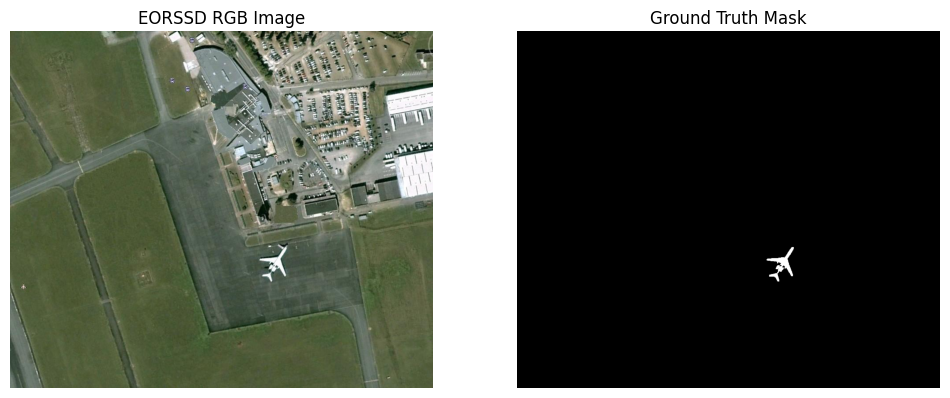

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("EORSSD RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

Converting the raw EORSSD files into tensors

In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms.functional as TF


class EORSSDDataset(Dataset):

    def __init__(self, image_dir, mask_dir, image_size=(512, 512)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

        self.image_files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith(".jpg")
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        image_name = self.image_files[idx]
        image_id = os.path.splitext(image_name)[0]

        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        mask_path = os.path.join(
            self.mask_dir,
            image_id + ".png"
        )

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = image.resize(
            self.image_size,
            Image.BILINEAR
        )

        mask = mask.resize(
            self.image_size,
            Image.NEAREST
        )

        image = TF.to_tensor(image)

        mask = np.array(mask)
        mask = (mask > 127).astype(np.float32)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

Create Training and Testing Datasets

In [ ]:
train_dataset = EORSSDDataset(
    train_images,
    train_labels,
    image_size=(512, 512)
)

test_dataset = EORSSDDataset(
    test_images,
    test_labels,
    image_size=(512, 512)
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1400
Testing samples: 600


In [ ]:
image, mask = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min().item(), image.max().item())

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask values:", torch.unique(mask))

Image shape: torch.Size([3, 512, 512])
Image dtype: torch.float32
Image range: 0.0 1.0
Mask shape: torch.Size([1, 512, 512])
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


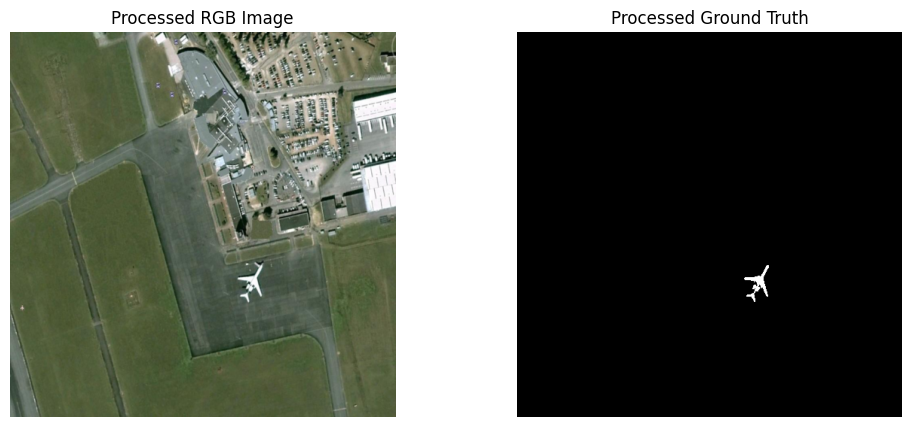

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("Processed RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.squeeze(0), cmap="gray")
plt.title("Processed Ground Truth")
plt.axis("off")

plt.show()

Build the RGB Generator

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import efficientnet_b0

EfficientNet Encoder

In [ ]:
class EfficientNetEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = efficientnet_b0(weights=None)
        self.features = backbone.features

    def forward(self, x):

        features = []

        for i, layer in enumerate(self.features):
            x = layer(x)

            if i in [1, 2, 3, 5, 7]:
                features.append(x)

        return features

Decoder Block

In [ ]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels + skip_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(out_channels)
        self.bn2 = nn.BatchNorm2d(out_channels)

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))

        return x

SAER

In [ ]:
class SAER(nn.Module):
    def __init__(self, channels):
        super().__init__()

        # Channel attention
        self.channel_conv = nn.Conv1d(
            1,
            1,
            kernel_size=3,
            padding=1,
            bias=False
        )

        # Spatial attention
        self.spatial_conv = nn.Conv2d(
            2,
            1,
            kernel_size=7,
            padding=3,
            bias=False
        )

    def forward(self, x):

        # Channel attention
        avg = F.adaptive_avg_pool2d(x, 1)
        max_pool = F.adaptive_max_pool2d(x, 1)

        channel = avg + max_pool

        b, c, _, _ = channel.shape

        channel = channel.view(b, 1, c)
        channel = self.channel_conv(channel)
        channel = torch.sigmoid(channel)
        channel = channel.view(b, c, 1, 1)

        x = x * channel

        # Spatial attention
        avg_spatial = torch.mean(x, dim=1, keepdim=True)
        max_spatial = torch.max(x, dim=1, keepdim=True)[0]

        spatial = torch.cat(
            [avg_spatial, max_spatial],
            dim=1
        )

        spatial = torch.sigmoid(
            self.spatial_conv(spatial)
        )

        x = x * spatial

        return x

In [ ]:
class SegmentationHead(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            1,
            kernel_size=1
        )

    def forward(self, x):
        return self.conv(x)


class EdgeHead(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            1,
            kernel_size=1
        )

    def forward(self, x):
        return self.conv(x)

In [ ]:
class EORSSDGenerator(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = EfficientNetEncoder()

        self.deformable_attention = DeformableAttention(320)

        self.decoder1 = DecoderBlock(320, 112, 256)
        self.decoder2 = DecoderBlock(256, 40, 128)
        self.decoder3 = DecoderBlock(128, 24, 64)
        self.decoder4 = DecoderBlock(64, 16, 32)

        self.saer = SAER(32)

        self.seg_head = SegmentationHead(32)
        self.edge_head = EdgeHead(32)

    def forward(self, x):

        features = self.encoder(x)

        f1, f2, f3, f4, f5 = features

        # Deformable attention
        f5 = self.deformable_attention(f5)

        x = f5

        x = self.decoder1(x, f4)
        x = self.decoder2(x, f3)
        x = self.decoder3(x, f2)
        x = self.decoder4(x, f1)

        x = self.saer(x)

        segmentation = self.seg_head(x)
        edge = self.edge_head(x)

        segmentation = F.interpolate(
            segmentation,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        edge = F.interpolate(
            edge,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        return segmentation, edge

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = EORSSDGenerator().to(device)

dummy_input = torch.randn(
    2, 3, 512, 512
).to(device)

segmentation, edge = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Segmentation output:", segmentation.shape)
print("Edge output:", edge.shape)

Input shape: torch.Size([2, 3, 512, 512])
Segmentation output: torch.Size([2, 1, 512, 512])
Edge output: torch.Size([2, 1, 512, 512])


In [ ]:
class DeformableAttention(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.offset_conv = nn.Conv2d(
            channels,
            2,
            kernel_size=3,
            padding=1
        )

        self.attention_conv = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.attention = nn.Conv2d(
            channels,
            1,
            kernel_size=1
        )

        self.proj = nn.Conv2d(
            channels,
            channels,
            kernel_size=1
        )

    def forward(self, x):

        b, c, h, w = x.shape

        offsets = self.offset_conv(x)

        yy, xx = torch.meshgrid(
            torch.linspace(-1, 1, h, device=x.device),
            torch.linspace(-1, 1, w, device=x.device),
            indexing="ij"
        )

        base_grid = torch.stack(
            (xx, yy),
            dim=-1
        )

        base_grid = base_grid.unsqueeze(0).repeat(b, 1, 1, 1)

        offset_x = offsets[:, 0] / max(w / 2, 1)
        offset_y = offsets[:, 1] / max(h / 2, 1)

        sampling_grid = base_grid.clone()

        sampling_grid[:, :, :, 0] += offset_x
        sampling_grid[:, :, :, 1] += offset_y

        sampled = F.grid_sample(
            x,
            sampling_grid,
            mode="bilinear",
            padding_mode="border",
            align_corners=True
        )

        features = self.attention_conv(sampled)

        weights = torch.sigmoid(
            self.attention(features)
        )

        out = sampled * weights

        out = self.proj(out)

        return out + x

In [ ]:
test_attention = DeformableAttention(320).to(device)

x = torch.randn(
    2, 320, 32, 32
).to(device)

y = test_attention(x)

print("Input :", x.shape)
print("Output:", y.shape)

Input : torch.Size([2, 320, 32, 32])
Output: torch.Size([2, 320, 32, 32])


In [ ]:
model = EORSSDGenerator().to(device)

dummy_input = torch.randn(
    2, 3, 512, 512
).to(device)

segmentation, edge = model(dummy_input)

print("Input:", dummy_input.shape)
print("Segmentation:", segmentation.shape)
print("Edge:", edge.shape)

Input: torch.Size([2, 3, 512, 512])
Segmentation: torch.Size([2, 1, 512, 512])
Edge: torch.Size([2, 1, 512, 512])


In [ ]:
class PatchDiscriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                128, 256,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                256, 1,
                kernel_size=4,
                stride=1,
                padding=1
            )
        )

    def forward(self, x):
        return self.model(x)

In [ ]:
discriminator = PatchDiscriminator().to(device)

test_mask = torch.randn(
    2, 1, 512, 512
).to(device)

disc_output = discriminator(test_mask)

print("Input:", test_mask.shape)
print("Discriminator output:", disc_output.shape)

Input: torch.Size([2, 1, 512, 512])
Discriminator output: torch.Size([2, 1, 63, 63])


In [ ]:
def dice_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (
        (2 * intersection + smooth) /
        (pred.sum(dim=1) + target.sum(dim=1) + smooth)
    )

    return 1 - dice.mean()

In [ ]:
bce_loss = nn.BCEWithLogitsLoss()

In [ ]:
def supervised_segmentation_loss(pred, target):
    dice = dice_loss(pred, target)
    bce = bce_loss(pred, target)

    return dice + bce

In [ ]:
def mask_to_edge(mask):
    edge = torch.zeros_like(mask)

    edge[:, :, 1:, :] = torch.maximum(
        edge[:, :, 1:, :],
        torch.abs(mask[:, :, 1:, :] - mask[:, :, :-1, :])
    )

    edge[:, :, :, 1:] = torch.maximum(
        edge[:, :, :, 1:],
        torch.abs(mask[:, :, :, 1:] - mask[:, :, :, :-1])
    )

    return (edge > 0).float()

In [ ]:
def supervised_edge_loss(edge_pred, mask):

    edge_target = mask_to_edge(mask)

    return bce_loss(edge_pred, edge_target)

In [ ]:
def supervised_loss(seg_pred, edge_pred, mask):

    seg_loss = supervised_segmentation_loss(
        seg_pred,
        mask
    )

    edge_loss = supervised_edge_loss(
        edge_pred,
        mask
    )

    total_loss = seg_loss + 0.1 * edge_loss

    return total_loss

In [ ]:
batch_size = 2

pred_seg = torch.randn(
    batch_size, 1, 512, 512
).to(device)

pred_edge = torch.randn(
    batch_size, 1, 512, 512
).to(device)

target_mask = torch.randint(
    0, 2,
    (batch_size, 1, 512, 512)
).float().to(device)

loss = supervised_loss(
    pred_seg,
    pred_edge,
    target_mask
)

print("Supervised loss:", loss.item())

Supervised loss: 1.387697696685791


ORPL

In [ ]:
class OffsetHead(nn.Module):

    def __init__(self, in_channels):
        super().__init__()

        self.offset = nn.Sequential(
            nn.Conv2d(
                in_channels,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                32,
                2,
                kernel_size=1
            )
        )

    def forward(self, x):
        return self.offset(x)

In [ ]:
offset_head = OffsetHead(32).to(device)

test_features = torch.randn(
    2, 32, 512, 512
).to(device)

offsets = offset_head(test_features)

print("Feature shape:", test_features.shape)
print("Offset shape:", offsets.shape)

Feature shape: torch.Size([2, 32, 512, 512])
Offset shape: torch.Size([2, 2, 512, 512])


In [ ]:
def rectify_pseudo_label(pseudo_prob, offsets, boundary_mask):
    """
    pseudo_prob:   [B, 1, H, W]
    offsets:       [B, 2, H, W]
    boundary_mask: [B, 1, H, W]
    """

    B, _, H, W = pseudo_prob.shape

    yy, xx = torch.meshgrid(
        torch.linspace(-1, 1, H, device=pseudo_prob.device),
        torch.linspace(-1, 1, W, device=pseudo_prob.device),
        indexing="ij"
    )

    base_grid = torch.stack(
        [xx, yy],
        dim=-1
    ).unsqueeze(0).repeat(B, 1, 1, 1)

    offset_x = offsets[:, 0] / max(W / 2, 1)
    offset_y = offsets[:, 1] / max(H / 2, 1)

    sampling_grid = base_grid.clone()

    sampling_grid[:, :, :, 0] += offset_x
    sampling_grid[:, :, :, 1] += offset_y

    sampled_prob = F.grid_sample(
        pseudo_prob,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True
    )

    refined_prob = torch.where(
        boundary_mask.bool(),
        sampled_prob,
        pseudo_prob
    )

    reliability = 1 - torch.abs(
        pseudo_prob - refined_prob
    )

    return refined_prob, reliability

In [ ]:
def get_boundary_band(mask, kernel_size=3):

    dilated = F.max_pool2d(
        mask,
        kernel_size=kernel_size,
        stride=1,
        padding=kernel_size // 2
    )

    eroded = -F.max_pool2d(
        -mask,
        kernel_size=kernel_size,
        stride=1,
        padding=kernel_size // 2
    )

    boundary = (dilated - eroded) > 0

    return boundary.float()

In [ ]:
pseudo_prob = torch.sigmoid(
    torch.randn(2, 1, 512, 512)
).to(device)

pseudo_mask = (pseudo_prob > 0.5).float()

boundary = get_boundary_band(pseudo_mask)

offsets = torch.randn(
    2, 2, 512, 512
).to(device)

refined_prob, reliability = rectify_pseudo_label(
    pseudo_prob,
    offsets,
    boundary
)

print("Pseudo probability:", pseudo_prob.shape)
print("Boundary:", boundary.shape)
print("Offsets:", offsets.shape)
print("Refined probability:", refined_prob.shape)
print("Reliability:", reliability.shape)

Pseudo probability: torch.Size([2, 1, 512, 512])
Boundary: torch.Size([2, 1, 512, 512])
Offsets: torch.Size([2, 2, 512, 512])
Refined probability: torch.Size([2, 1, 512, 512])
Reliability: torch.Size([2, 1, 512, 512])


In [ ]:
class EORSSDGenerator(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = EfficientNetEncoder()

        self.deformable_attention = DeformableAttention(320)

        self.decoder1 = DecoderBlock(320, 112, 256)
        self.decoder2 = DecoderBlock(256, 40, 128)
        self.decoder3 = DecoderBlock(128, 24, 64)
        self.decoder4 = DecoderBlock(64, 16, 32)

        self.saer = SAER(32)

        self.seg_head = SegmentationHead(32)
        self.edge_head = EdgeHead(32)
        self.offset_head = OffsetHead(32)

    def forward(self, x):

        features = self.encoder(x)

        f1, f2, f3, f4, f5 = features

        f5 = self.deformable_attention(f5)

        x = f5

        x = self.decoder1(x, f4)
        x = self.decoder2(x, f3)
        x = self.decoder3(x, f2)
        x = self.decoder4(x, f1)

        x = self.saer(x)

        segmentation = self.seg_head(x)
        edge = self.edge_head(x)
        offsets = self.offset_head(x)

        segmentation = F.interpolate(
            segmentation,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        edge = F.interpolate(
            edge,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        offsets = F.interpolate(
            offsets,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        return segmentation, edge, offsets

In [ ]:
model = EORSSDGenerator().to(device)

dummy_input = torch.randn(
    2, 3, 512, 512
).to(device)

segmentation, edge, offsets = model(dummy_input)

print("Input:", dummy_input.shape)
print("Segmentation:", segmentation.shape)
print("Edge:", edge.shape)
print("Offsets:", offsets.shape)

Input: torch.Size([2, 3, 512, 512])
Segmentation: torch.Size([2, 1, 512, 512])
Edge: torch.Size([2, 1, 512, 512])
Offsets: torch.Size([2, 2, 512, 512])


In [ ]:
def create_offset_target(mask, max_distance=10):

    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)

    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device
    )

    for b in range(B):

        boundary_points = torch.nonzero(
            boundary[b, 0],
            as_tuple=False
        )

        foreground_points = torch.nonzero(
            mask[b, 0] > 0.5,
            as_tuple=False
        )

        if boundary_points.numel() == 0:
            continue

        if foreground_points.numel() == 0:
            continue

        for point in boundary_points:

            y, x = point

            distances = torch.sqrt(
                (foreground_points[:, 0] - y).float() ** 2 +
                (foreground_points[:, 1] - x).float() ** 2
            )

            valid = distances <= max_distance

            if valid.any():

                valid_distances = distances.clone()
                valid_distances[~valid] = float("inf")

                nearest_idx = torch.argmin(
                    valid_distances
                )

                target_y, target_x = foreground_points[
                    nearest_idx
                ]

                offsets[b, 0, y, x] = (
                    target_x.float() - x.float()
                )

                offsets[b, 1, y, x] = (
                    target_y.float() - y.float()
                )

    return offsets

In [ ]:
image, mask = train_dataset[0]

mask_batch = mask.unsqueeze(0).to(device)

offset_target = create_offset_target(
    mask_batch,
    max_distance=10
)

print("Mask:", mask_batch.shape)
print("Offset target:", offset_target.shape)
print(
    "Offset range:",
    offset_target.min().item(),
    offset_target.max().item()
)

Mask: torch.Size([1, 1, 512, 512])
Offset target: torch.Size([1, 2, 512, 512])
Offset range: -1.0 1.0


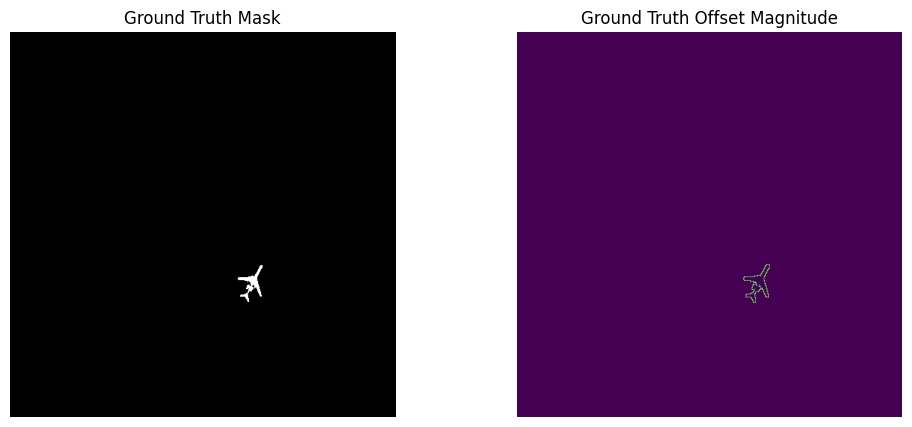

In [ ]:
offset_magnitude = torch.sqrt(
    offset_target[:, 0] ** 2 +
    offset_target[:, 1] ** 2
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask.squeeze().cpu(), cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(offset_magnitude.squeeze().cpu())
plt.title("Ground Truth Offset Magnitude")
plt.axis("off")

plt.show()

Proper deep-interior offset target

In [ ]:
import torch
import torch.nn.functional as F


def get_deep_interior(mask, kernel_size=11):
    """
    Finds pixels that are safely inside the foreground object.
    """

    # Erosion: pixel remains foreground only if its neighborhood
    # is also foreground.
    eroded = -F.max_pool2d(
        -mask,
        kernel_size=kernel_size,
        stride=1,
        padding=kernel_size // 2
    )

    return (eroded > 0.5).float()


def create_proper_offset_target(mask, kernel_size=11):
    """
    Creates an offset target from boundary pixels
    toward the nearest deep-interior pixel.
    """

    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)
    interior = get_deep_interior(
        mask,
        kernel_size=kernel_size
    )

    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device
    )

    for b in range(B):

        boundary_points = torch.nonzero(
            boundary[b, 0],
            as_tuple=False
        )

        interior_points = torch.nonzero(
            interior[b, 0],
            as_tuple=False
        )

        # No valid boundary or interior
        if boundary_points.numel() == 0:
            continue

        if interior_points.numel() == 0:
            continue

        for point in boundary_points:

            y, x = point

            distances = (
                (interior_points[:, 0] - y).float() ** 2 +
                (interior_points[:, 1] - x).float() ** 2
            )

            nearest_idx = torch.argmin(distances)

            target_y, target_x = interior_points[
                nearest_idx
            ]

            offsets[b, 0, y, x] = (
                target_x.float() - x.float()
            )

            offsets[b, 1, y, x] = (
                target_y.float() - y.float()
            )

    return offsets, boundary, interior

In [ ]:
import cv2
import numpy as np


def get_adaptive_interior(mask):

    B, _, H, W = mask.shape

    interior = torch.zeros_like(mask)

    for b in range(B):

        binary = (
            mask[b, 0]
            .detach()
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        if binary.sum() == 0:
            continue

        # Distance of each foreground pixel from background
        distance = cv2.distanceTransform(
            binary,
            cv2.DIST_L2,
            5
        )

        max_distance = distance.max()

        if max_distance <= 0:
            continue

        # Keep pixels that are relatively deep inside
        threshold = max(1.0, 0.5 * max_distance)

        interior_np = (
            (distance >= threshold) &
            (binary > 0)
        ).astype(np.float32)

        interior[b, 0] = torch.from_numpy(
            interior_np
        ).to(mask.device)

    return interior

In [ ]:
def create_adaptive_offset_target(mask):

    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)

    interior = get_adaptive_interior(mask)

    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device
    )

    for b in range(B):

        boundary_points = torch.nonzero(
            boundary[b, 0],
            as_tuple=False
        )

        interior_points = torch.nonzero(
            interior[b, 0],
            as_tuple=False
        )

        if boundary_points.numel() == 0:
            continue

        if interior_points.numel() == 0:
            continue

        for point in boundary_points:

            y, x = point

            distances = (
                (interior_points[:, 0] - y).float() ** 2 +
                (interior_points[:, 1] - x).float() ** 2
            )

            nearest_idx = torch.argmin(distances)

            target_y, target_x = interior_points[
                nearest_idx
            ]

            offsets[b, 0, y, x] = (
                target_x.float() - x.float()
            )

            offsets[b, 1, y, x] = (
                target_y.float() - y.float()
            )

    return offsets, boundary, interior

In [ ]:
image, mask = train_dataset[0]

mask_batch = mask.unsqueeze(0).to(device)

proper_offsets, boundary, interior = \
    create_adaptive_offset_target(mask_batch)

print("Mask:", mask_batch.shape)
print("Boundary:", boundary.shape)
print("Interior pixels:", interior.sum().item())
print("Offset target:", proper_offsets.shape)

Mask: torch.Size([1, 1, 512, 512])
Boundary: torch.Size([1, 1, 512, 512])
Interior pixels: 70.0
Offset target: torch.Size([1, 2, 512, 512])


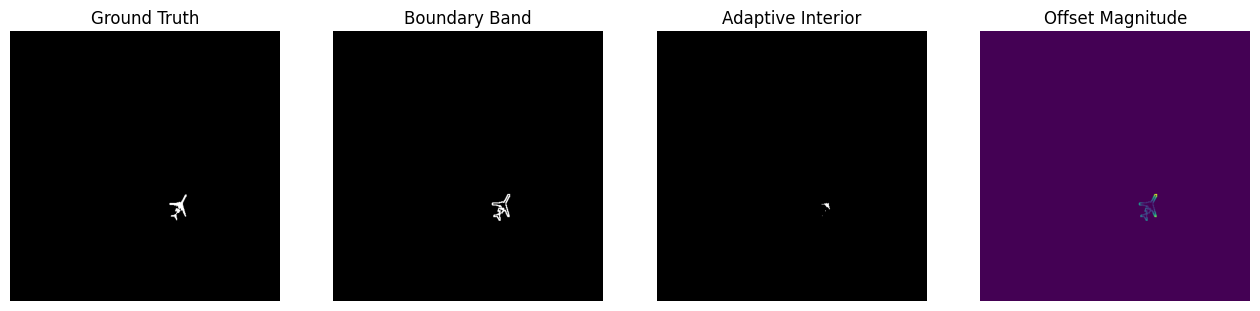

In [ ]:
offset_magnitude = torch.sqrt(
    proper_offsets[:, 0] ** 2 +
    proper_offsets[:, 1] ** 2
)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(mask_batch[0, 0].cpu(), cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(boundary[0, 0].cpu(), cmap="gray")
plt.title("Boundary Band")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(interior[0, 0].cpu(), cmap="gray")
plt.title("Adaptive Interior")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(offset_magnitude[0].cpu())
plt.title("Offset Magnitude")
plt.axis("off")

plt.show()

In [ ]:
import numpy as np
from scipy.ndimage import distance_transform_edt


def create_fast_offset_target(mask):
    """
    Creates adaptive offset targets.

    For each boundary pixel, points toward the nearest
    reliable interior pixel on the same foreground/background side.
    """

    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)

    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device
    )

    for b in range(B):

        binary = (
            mask[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        boundary_np = (
            boundary[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        if not binary.any():
            continue

        # Distance inside foreground
        fg_distance = distance_transform_edt(binary)

        # Adaptive foreground interior
        max_fg = fg_distance.max()

        if max_fg > 0:
            fg_interior = (
                (fg_distance >= 0.5 * max_fg) &
                binary
            )
        else:
            fg_interior = binary

        # Distance inside background
        bg_distance = distance_transform_edt(~binary)

        max_bg = bg_distance.max()

        if max_bg > 0:
            bg_interior = (
                (bg_distance >= 0.5 * max_bg) &
                (~binary)
            )
        else:
            bg_interior = ~binary

        # Coordinates of interior pixels
        fg_coords = np.argwhere(fg_interior)
        bg_coords = np.argwhere(bg_interior)

        boundary_coords = np.argwhere(boundary_np)

        if len(fg_coords) == 0:
            continue

        # Calculate offsets for boundary pixels
        for y, x in boundary_coords:

            if binary[y, x]:
                candidates = fg_coords
            else:
                candidates = bg_coords

            if len(candidates) == 0:
                continue

            distances = (
                (candidates[:, 0] - y) ** 2 +
                (candidates[:, 1] - x) ** 2
            )

            nearest = candidates[np.argmin(distances)]

            target_y, target_x = nearest

            offsets[b, 0, y, x] = (
                float(target_x - x)
            )

            offsets[b, 1, y, x] = (
                float(target_y - y)
            )

    return offsets, boundary

In [ ]:
image, mask = train_dataset[0]

mask_batch = mask.unsqueeze(0).to(device)

fast_offsets, boundary = create_fast_offset_target(
    mask_batch
)

print("Mask:", mask_batch.shape)
print("Boundary:", boundary.shape)
print("Offsets:", fast_offsets.shape)
print(
    "Non-zero offset pixels:",
    (fast_offsets.abs().sum(dim=1) > 0).sum().item()
)

Mask: torch.Size([1, 1, 512, 512])
Boundary: torch.Size([1, 1, 512, 512])
Offsets: torch.Size([1, 2, 512, 512])
Non-zero offset pixels: 512


In [ ]:
def offset_loss(predicted_offsets, target_offsets, boundary):

    mask = boundary.expand_as(predicted_offsets)

    loss = F.smooth_l1_loss(
        predicted_offsets[mask.bool()],
        target_offsets[mask.bool()]
    )

    return loss

In [ ]:
predicted_offsets = torch.randn(
    1, 2, 512, 512
).to(device)

loss = offset_loss(
    predicted_offsets,
    fast_offsets,
    boundary
)

print("Offset loss:", loss.item())

Offset loss: 77.40641784667969


In [ ]:
print("Target offset min:",
      fast_offsets.min().item())

print("Target offset max:",
      fast_offsets.max().item())

print("Target offset mean:",
      fast_offsets.abs().mean().item())

print("Target offset max magnitude:",
      torch.sqrt(
          fast_offsets[:, 0]**2 +
          fast_offsets[:, 1]**2
      ).max().item())

Target offset min: -238.0
Target offset max: 188.0
Target offset mean: 0.1520557403564453
Target offset max magnitude: 240.1874237060547


In [ ]:
def create_fast_offset_target(mask, max_offset=10):

    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)

    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device
    )

    for b in range(B):

        binary = (
            mask[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        boundary_np = (
            boundary[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        if not binary.any():
            continue

        fg_distance = distance_transform_edt(binary)
        bg_distance = distance_transform_edt(~binary)

        max_fg = fg_distance.max()
        max_bg = bg_distance.max()

        # Adaptive foreground interior
        if max_fg > 0:
            fg_interior = (
                (fg_distance >= 0.5 * max_fg) &
                binary
            )
        else:
            fg_interior = binary

        # Adaptive background interior
        if max_bg > 0:
            bg_interior = (
                (bg_distance >= 0.5 * max_bg) &
                (~binary)
            )
        else:
            bg_interior = ~binary

        fg_coords = np.argwhere(fg_interior)
        bg_coords = np.argwhere(bg_interior)

        boundary_coords = np.argwhere(boundary_np)

        for y, x in boundary_coords:

            if binary[y, x]:
                candidates = fg_coords
            else:
                candidates = bg_coords

            if len(candidates) == 0:
                continue

            dy = candidates[:, 0] - y
            dx = candidates[:, 1] - x

            distances = np.sqrt(
                dx.astype(np.float32) ** 2 +
                dy.astype(np.float32) ** 2
            )

            valid = distances <= max_offset

            if not valid.any():
                continue

            valid_distances = distances.copy()
            valid_distances[~valid] = np.inf

            nearest_idx = np.argmin(valid_distances)

            target_y, target_x = candidates[nearest_idx]

            offsets[b, 0, y, x] = float(target_x - x)
            offsets[b, 1, y, x] = float(target_y - y)

    return offsets, boundary

In [ ]:
fast_offsets, boundary = create_fast_offset_target(
    mask_batch,
    max_offset=10
)

In [ ]:
print("Target offset min:",
      fast_offsets.min().item())

print("Target offset max:",
      fast_offsets.max().item())

print("Target offset mean:",
      fast_offsets.abs().mean().item())

print("Target offset max magnitude:",
      torch.sqrt(
          fast_offsets[:, 0]**2 +
          fast_offsets[:, 1]**2
      ).max().item())

Target offset min: -9.0
Target offset max: 10.0
Target offset mean: 0.002094268798828125
Target offset max magnitude: 10.0


In [ ]:
model = EORSSDGenerator().to(device)

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [ ]:
image, mask = train_dataset[0]

image = image.unsqueeze(0).to(device)
mask = mask.unsqueeze(0).to(device)

In [ ]:
seg_pred, edge_pred, offset_pred = model(image)

print("Segmentation:", seg_pred.shape)
print("Edge:", edge_pred.shape)
print("Offset:", offset_pred.shape)

Segmentation: torch.Size([1, 1, 512, 512])
Edge: torch.Size([1, 1, 512, 512])
Offset: torch.Size([1, 2, 512, 512])


In [ ]:
target_offsets, boundary = create_fast_offset_target(
    mask,
    max_offset=10
)

In [ ]:
loss = offset_loss(
    offset_pred,
    target_offsets,
    boundary
)

print("Initial offset loss:", loss.item())

Initial offset loss: 0.8936874270439148


In [ ]:
optimizer.zero_grad()

loss.backward()

optimizer.step()

print("One training step completed.")

One training step completed.


In [ ]:
# Check that the Offset Head receives gradients

offset_params = list(model.offset_head.parameters())

for param in offset_params:
    if param.grad is not None:
        print("Gradient mean:", param.grad.abs().mean().item())
        break


Gradient mean: 1.9153043467667885e-05


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Number of batches:", len(train_loader))

Number of batches: 350


In [ ]:
LAMBDA_EDGE = 0.1
LAMBDA_OFFSET = 0.1


def full_supervised_loss(
    seg_pred,
    edge_pred,
    offset_pred,
    mask,
    target_offsets,
    boundary
):

    seg_loss = supervised_segmentation_loss(
        seg_pred,
        mask
    )

    edge_loss = supervised_edge_loss(
        edge_pred,
        mask
    )

    off_loss = offset_loss(
        offset_pred,
        target_offsets,
        boundary
    )

    total = (
        seg_loss
        + LAMBDA_EDGE * edge_loss
        + LAMBDA_OFFSET * off_loss
    )

    return total, seg_loss, edge_loss, off_loss

In [ ]:
model.train()

images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

seg_pred, edge_pred, offset_pred = model(images)

target_offsets, boundary = create_fast_offset_target(
    masks,
    max_offset=10
)

total_loss, seg_loss, edge_loss, off_loss = full_supervised_loss(
    seg_pred,
    edge_pred,
    offset_pred,
    masks,
    target_offsets,
    boundary
)

optimizer.zero_grad()

total_loss.backward()

optimizer.step()

print("Total loss :", total_loss.item())
print("Seg loss   :", seg_loss.item())
print("Edge loss  :", edge_loss.item())
print("Offset loss:", off_loss.item())

Total loss : 1.558056116104126
Seg loss   : 1.47951078414917
Edge loss  : 0.611221969127655
Offset loss: 0.17423202097415924


In [ ]:
from scipy.ndimage import distance_transform_edt
import numpy as np
import torch

def create_fast_offset_target(mask, max_offset=10):
    B, _, H, W = mask.shape

    boundary = get_boundary_band(mask)
    offsets = torch.zeros(
        B, 2, H, W,
        device=mask.device,
        dtype=torch.float32
    )

    for b in range(B):

        binary = (
            mask[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        boundary_np = (
            boundary[b, 0]
            .detach()
            .cpu()
            .numpy() > 0.5
        )

        if not binary.any() or not boundary_np.any():
            continue

        fg_distance = distance_transform_edt(binary)
        bg_distance = distance_transform_edt(~binary)

        max_fg = fg_distance.max()
        max_bg = bg_distance.max()

        if max_fg > 0:
            fg_interior = (
                (fg_distance >= 0.5 * max_fg) &
                binary
            )
        else:
            fg_interior = binary

        if max_bg > 0:
            bg_interior = (
                (bg_distance >= 0.5 * max_bg) &
                (~binary)
            )
        else:
            bg_interior = ~binary

        # Nearest foreground interior
        if fg_interior.any():
            _, indices_fg = distance_transform_edt(
                ~fg_interior,
                return_distances=True,
                return_indices=True
            )

        # Nearest background interior
        if bg_interior.any():
            _, indices_bg = distance_transform_edt(
                ~bg_interior,
                return_distances=True,
                return_indices=True
            )

        ys, xs = np.where(boundary_np)

        for y, x in zip(ys, xs):

            if binary[y, x] and fg_interior.any():
                target_y = indices_fg[0, y, x]
                target_x = indices_fg[1, y, x]

            elif (not binary[y, x]) and bg_interior.any():
                target_y = indices_bg[0, y, x]
                target_x = indices_bg[1, y, x]

            else:
                continue

            dx = target_x - x
            dy = target_y - y

            distance = np.sqrt(dx**2 + dy**2)

            if distance <= max_offset:
                offsets[b, 0, y, x] = float(dx)
                offsets[b, 1, y, x] = float(dy)

    return offsets, boundary

In [ ]:
target_offsets, boundary = create_fast_offset_target(
    masks,
    max_offset=10
)

print("Target shape:", target_offsets.shape)
print("Boundary shape:", boundary.shape)
print("Max offset:", target_offsets.abs().max().item())
print("Mean absolute offset:", target_offsets.abs().mean().item())

Target shape: torch.Size([4, 2, 512, 512])
Boundary shape: torch.Size([4, 1, 512, 512])
Max offset: 10.0
Mean absolute offset: 0.0016322135925292969


In [ ]:
num_epochs = 1

model.train()

for epoch in range(num_epochs):

    running_loss = 0
    running_seg = 0
    running_edge = 0
    running_offset = 0

    for batch_idx, (images, masks) in enumerate(train_loader):

        images = images.to(device)
        masks = masks.to(device)

        seg_pred, edge_pred, offset_pred = model(images)

        target_offsets, boundary = create_fast_offset_target(
            masks,
            max_offset=10
        )

        total_loss, seg_loss, edge_loss, off_loss = full_supervised_loss(
            seg_pred,
            edge_pred,
            offset_pred,
            masks,
            target_offsets,
            boundary
        )

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()
        running_seg += seg_loss.item()
        running_edge += edge_loss.item()
        running_offset += off_loss.item()

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Batch {batch_idx+1}/{len(train_loader)} | "
                f"Loss: {total_loss.item():.4f}"
            )

    n = len(train_loader)

    print("\nEpoch", epoch + 1, "completed")
    print("Average Total Loss :", running_loss / n)
    print("Average Seg Loss   :", running_seg / n)
    print("Average Edge Loss  :", running_edge / n)
    print("Average Offset Loss:", running_offset / n)

Batch 50/350 | Loss: 1.6089
Batch 100/350 | Loss: 1.6377
Batch 150/350 | Loss: 1.4058
Batch 200/350 | Loss: 1.4566
Batch 250/350 | Loss: 1.5005
Batch 300/350 | Loss: 1.2934
Batch 350/350 | Loss: 1.3151

Epoch 1 completed
Average Total Loss : 1.4822939120020184
Average Seg Loss   : 1.3781048706599643
Average Edge Loss  : 0.5032107191426414
Average Offset Loss: 0.538679715395639


In [ ]:
test_image_dir = "/content/drive/MyDrive/EORSSD/test-images"
test_mask_dir = "/content/drive/MyDrive/EORSSD/test-labels"

test_dataset = EORSSDDataset(
    test_image_dir,
    test_mask_dir,
    image_size=(512, 512)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 600
Test batches: 150


In [ ]:
def calculate_metrics(pred, target, threshold=0.5):

    pred = (torch.sigmoid(pred) > threshold).float()

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    union = pred.sum(dim=1) + target.sum(dim=1) - intersection

    iou = (intersection + 1e-6) / (union + 1e-6)

    precision = (intersection + 1e-6) / (
        pred.sum(dim=1) + 1e-6
    )

    recall = (intersection + 1e-6) / (
        target.sum(dim=1) + 1e-6
    )

    f1 = (
        2 * precision * recall /
        (precision + recall + 1e-6)
    )

    return iou.mean().item(), f1.mean().item()

In [ ]:
def validate(model, loader):

    model.eval()

    total_iou = 0
    total_f1 = 0
    total_loss = 0
    count = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            seg_pred, edge_pred, offset_pred = model(images)

            loss = supervised_segmentation_loss(
                seg_pred,
                masks
            )

            iou, f1 = calculate_metrics(
                seg_pred,
                masks
            )

            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            total_iou += iou * batch_size
            total_f1 += f1 * batch_size
            count += batch_size

    return (
        total_loss / count,
        total_iou / count,
        total_f1 / count
    )

In [ ]:
val_loss, val_iou, val_f1 = validate(
    model,
    test_loader
)

print("Validation Loss :", val_loss)
print("Validation mIoU :", val_iou)
print("Validation F1   :", val_f1)

Validation Loss : 10.188433005809785
Validation mIoU : 0.2082323192747952
Validation F1   : 0.28243447406860495


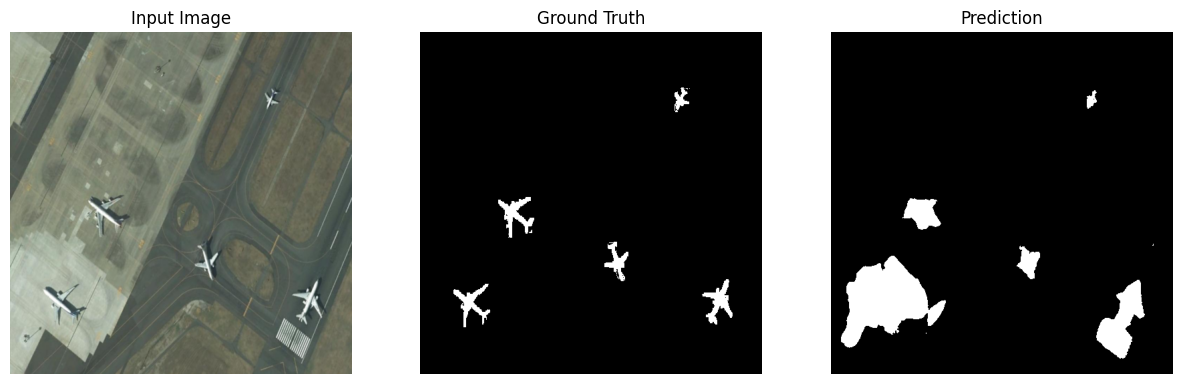

In [ ]:
import matplotlib.pyplot as plt

model.eval()

image, mask = test_dataset[0]

with torch.no_grad():
    pred, edge, offset = model(
        image.unsqueeze(0).to(device)
    )

pred_prob = torch.sigmoid(pred)[0, 0].cpu().numpy()
pred_mask = (pred_prob > 0.5).astype(float)

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask[0].numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_np, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask, cmap="gray")
plt.title("Prediction")
plt.axis("off")

plt.show()

In [ ]:
from torch.utils.data import random_split, DataLoader

train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images   :", len(train_subset))
print("Validation images :", len(val_subset))
print("Test images       :", len(test_dataset))

Training images   : 1260
Validation images : 140
Test images       : 600


In [ ]:
train_loader = DataLoader(
    train_subset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))

Train batches: 315
Val batches  : 35


In [ ]:
model = EORSSDGenerator().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Model reset and ready.")

Model reset and ready.


In [ ]:
num_epochs = 10

best_miou = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_f1": []
}

for epoch in range(num_epochs):

    model.train()

    running_loss = 0
    running_seg = 0
    running_edge = 0
    running_offset = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        seg_pred, edge_pred, offset_pred = model(images)

        target_offsets, boundary = create_fast_offset_target(
            masks,
            max_offset=10
        )

        total_loss, seg_loss, edge_loss, off_loss = (
            full_supervised_loss(
                seg_pred,
                edge_pred,
                offset_pred,
                masks,
                target_offsets,
                boundary
            )
        )

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()
        running_seg += seg_loss.item()
        running_edge += edge_loss.item()
        running_offset += off_loss.item()

    n = len(train_loader)

    avg_train_loss = running_loss / n

    val_loss, val_miou, val_f1 = validate(
        model,
        val_loader
    )

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)
    history["val_f1"].append(val_f1)

    print(
        f"\nEpoch {epoch+1}/{num_epochs}"
    )
    print(
        f"Train Loss : {avg_train_loss:.4f}"
    )
    print(
        f"Val Loss   : {val_loss:.4f}"
    )
    print(
        f"Val mIoU   : {val_miou:.4f}"
    )
    print(
        f"Val F1     : {val_f1:.4f}"
    )

    if val_miou > best_miou:

        best_miou = val_miou

        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/EORSSD_best_supervised.pth"
        )

        print("✓ Best model saved")


Epoch 1/10
Train Loss : 1.5430
Val Loss   : 2.2999
Val mIoU   : 0.1553
Val F1     : 0.2139
✓ Best model saved

Epoch 2/10
Train Loss : 1.3631
Val Loss   : 1.8631
Val mIoU   : 0.1975
Val F1     : 0.2730
✓ Best model saved

Epoch 3/10
Train Loss : 1.2626
Val Loss   : 1.2070
Val mIoU   : 0.3037
Val F1     : 0.3942
✓ Best model saved

Epoch 4/10
Train Loss : 1.1733
Val Loss   : 1.1396
Val mIoU   : 0.3157
Val F1     : 0.4035
✓ Best model saved

Epoch 5/10
Train Loss : 1.0997
Val Loss   : 1.0505
Val mIoU   : 0.3471
Val F1     : 0.4384
✓ Best model saved

Epoch 6/10
Train Loss : 1.0269
Val Loss   : 1.0490
Val mIoU   : 0.3965
Val F1     : 0.4876
✓ Best model saved

Epoch 7/10
Train Loss : 0.9582
Val Loss   : 0.9432
Val mIoU   : 0.4309
Val F1     : 0.5276
✓ Best model saved

Epoch 8/10
Train Loss : 0.8908
Val Loss   : 1.3713
Val mIoU   : 0.4178
Val F1     : 0.5137

Epoch 9/10
Train Loss : 0.8152
Val Loss   : 0.8719
Val mIoU   : 0.4384
Val F1     : 0.5302
✓ Best model saved

Epoch 10/10
Train L

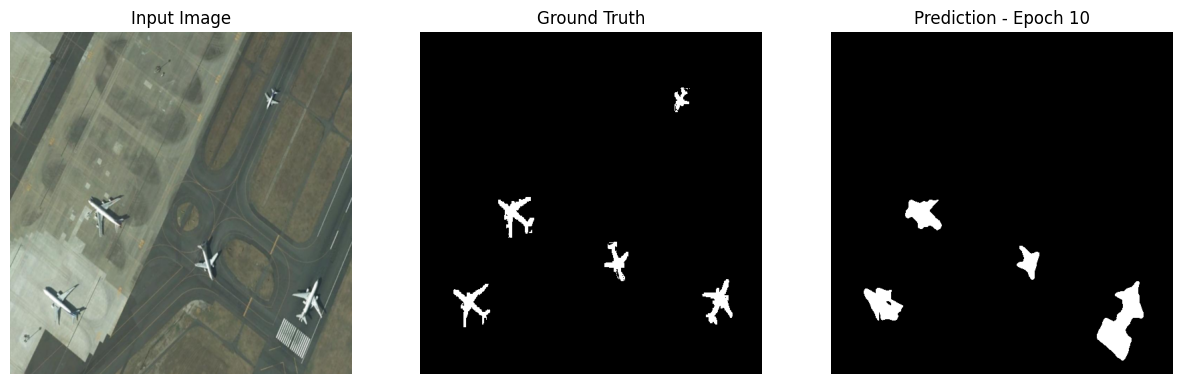

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_supervised.pth",
        map_location=device
    )
)

model.eval()

image, mask = test_dataset[0]

with torch.no_grad():
    seg_pred, edge_pred, offset_pred = model(
        image.unsqueeze(0).to(device)
    )

pred_prob = torch.sigmoid(seg_pred)[0, 0].cpu().numpy()
pred_mask = (pred_prob > 0.5).astype(float)

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask[0].numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_np, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask, cmap="gray")
plt.title("Prediction - Epoch 10")
plt.axis("off")

plt.show()

In [ ]:
from torch.utils.data import random_split

labeled_size = int(0.20 * len(train_subset))
unlabeled_size = len(train_subset) - labeled_size

labeled_subset, unlabeled_subset = random_split(
    train_subset,
    [labeled_size, unlabeled_size],
    generator=torch.Generator().manual_seed(42)
)

print("Labeled images   :", len(labeled_subset))
print("Unlabeled images :", len(unlabeled_subset))

Labeled images   : 252
Unlabeled images : 1008


In [ ]:
labeled_loader = DataLoader(
    labeled_subset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

unlabeled_loader = DataLoader(
    unlabeled_subset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Labeled batches   :", len(labeled_loader))
print("Unlabeled batches :", len(unlabeled_loader))

Labeled batches   : 63
Unlabeled batches : 252


In [ ]:
import torchvision.transforms.functional as TF
import random

def weak_augment(image):
    if random.random() < 0.5:
        image = TF.hflip(image)

    return image


def strong_augment(image):
    if random.random() < 0.5:
        image = TF.hflip(image)

    if random.random() < 0.5:
        image = TF.vflip(image)

    if random.random() < 0.5:
        angle = random.choice([-15, 15])
        image = TF.rotate(image, angle)

    if random.random() < 0.5:
        image = TF.adjust_brightness(
            image,
            brightness_factor=random.uniform(0.7, 1.3)
        )

    if random.random() < 0.5:
        image = TF.adjust_contrast(
            image,
            contrast_factor=random.uniform(0.7, 1.3)
        )

    return image


In [ ]:
image, mask = labeled_subset[0]

weak_image = weak_augment(image.clone())
strong_image = strong_augment(image.clone())

print("Original:", image.shape)
print("Weak    :", weak_image.shape)
print("Strong  :", strong_image.shape)

Original: torch.Size([3, 512, 512])
Weak    : torch.Size([3, 512, 512])
Strong  : torch.Size([3, 512, 512])


In [ ]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_supervised.pth",
        map_location=device
    )
)

model.train()

print("Best supervised model loaded.")

Best supervised model loaded.


In [ ]:
image, _ = unlabeled_subset[0]

weak_image = weak_augment(image.clone())

weak_image = weak_image.unsqueeze(0).to(device)

with torch.no_grad():
    seg_pred, edge_pred, offset_pred = model(weak_image)

pseudo_prob = torch.sigmoid(seg_pred)

pseudo_mask = (
    pseudo_prob > 0.5
).float()

boundary = get_boundary_band(
    pseudo_mask
)

refined_prob, reliability = rectify_pseudo_label(
    pseudo_prob,
    offset_pred.detach(),
    boundary
)

refined_mask = (
    refined_prob > 0.5
).float()

In [ ]:
print("Pseudo probability :", pseudo_prob.shape)
print("Pseudo mask        :", pseudo_mask.shape)
print("Boundary            :", boundary.shape)
print("Refined probability :", refined_prob.shape)
print("Reliability         :", reliability.shape)

print(
    "Average reliability:",
    reliability.mean().item()
)

Pseudo probability : torch.Size([1, 1, 512, 512])
Pseudo mask        : torch.Size([1, 1, 512, 512])
Boundary            : torch.Size([1, 1, 512, 512])
Refined probability : torch.Size([1, 1, 512, 512])
Reliability         : torch.Size([1, 1, 512, 512])
Average reliability: 0.9997439384460449


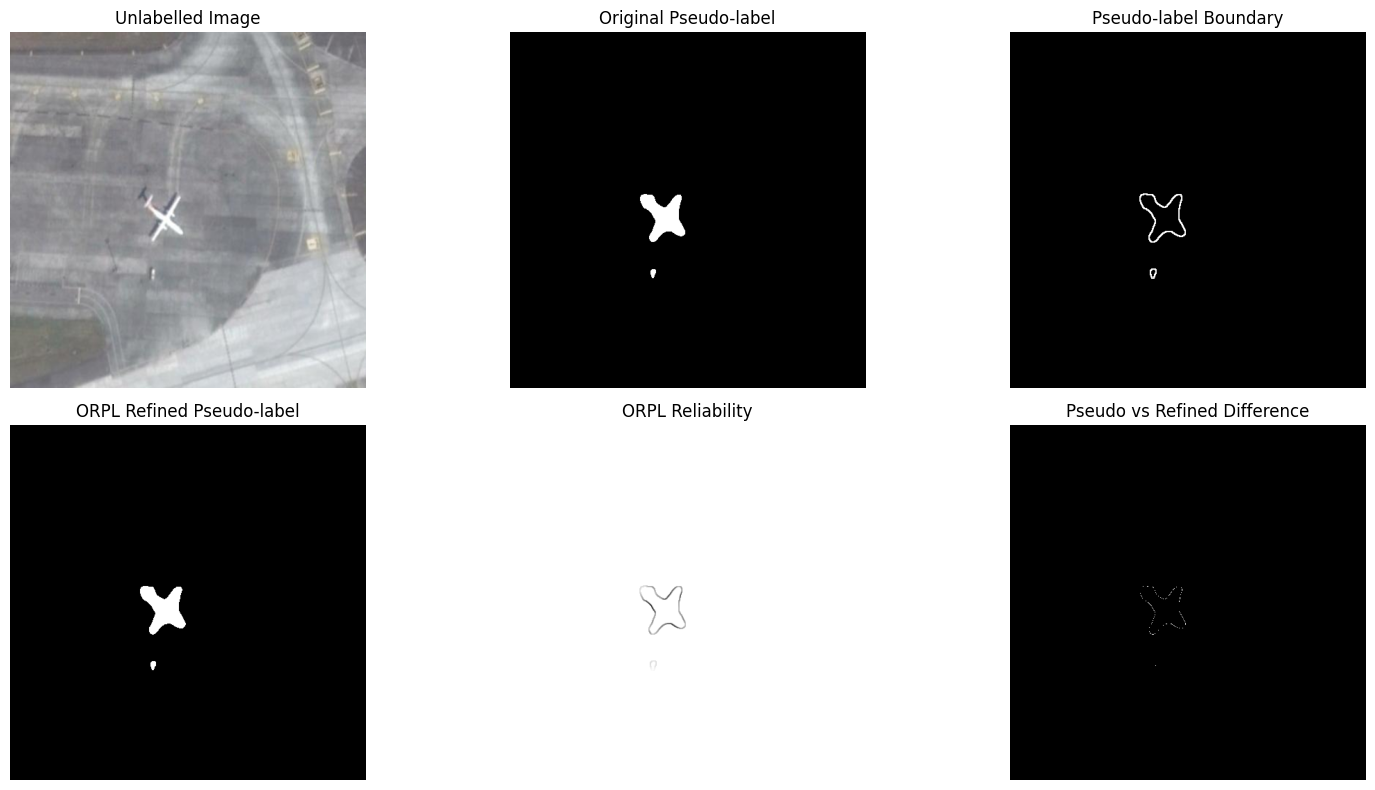

In [ ]:
import matplotlib.pyplot as plt

pseudo_np = pseudo_mask[0, 0].cpu().numpy()
refined_np = refined_mask[0, 0].cpu().numpy()
boundary_np = boundary[0, 0].cpu().numpy()
reliability_np = reliability[0, 0].cpu().numpy()

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(image.permute(1, 2, 0).numpy())
plt.title("Unlabelled Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(pseudo_np, cmap="gray")
plt.title("Original Pseudo-label")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(boundary_np, cmap="gray")
plt.title("Pseudo-label Boundary")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(refined_np, cmap="gray")
plt.title("ORPL Refined Pseudo-label")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(reliability_np, cmap="gray")
plt.title("ORPL Reliability")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(
    np.abs(pseudo_np - refined_np),
    cmap="gray"
)
plt.title("Pseudo vs Refined Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
boundary_pixels = boundary > 0

if boundary_pixels.any():

    boundary_reliability = reliability[boundary_pixels].mean().item()

    difference = torch.abs(
        pseudo_prob - refined_prob
    )

    boundary_difference = (
        difference[boundary_pixels].mean().item()
    )

    changed_pixels = (
        (difference > 0.01) & boundary_pixels
    ).sum().item()

    total_boundary_pixels = boundary_pixels.sum().item()

    print("Boundary reliability :", boundary_reliability)
    print("Boundary difference  :", boundary_difference)
    print("Changed boundary pixels :", changed_pixels)
    print("Total boundary pixels   :", total_boundary_pixels)

else:
    print("No boundary pixels found.")

Boundary reliability : 0.9130445122718811
Boundary difference  : 0.0869554951786995
Changed boundary pixels : 761
Total boundary pixels   : 772


In [ ]:
offset_magnitude = torch.sqrt(
    offset_pred[:, 0]**2 +
    offset_pred[:, 1]**2
)

print(
    "Mean predicted offset:",
    offset_magnitude.mean().item()
)

print(
    "Max predicted offset:",
    offset_magnitude.max().item()
)

Mean predicted offset: 0.0558306984603405
Max predicted offset: 1.6015559434890747


In [ ]:
target_offsets, boundary = create_fast_offset_target(
    masks,
    max_offset=10
)

target_magnitude = torch.sqrt(
    target_offsets[:, 0]**2 +
    target_offsets[:, 1]**2
)

valid = boundary[:, 0].bool()

valid_offsets = target_magnitude[valid]

print(
    "Mean target offset:",
    valid_offsets.mean().item()
)

print(
    "Max target offset:",
    valid_offsets.max().item()
)

print(
    "Boundary pixels:",
    valid.sum().item()
)

Mean target offset: 2.9922523498535156
Max target offset: 10.0
Boundary pixels: 3491


In [ ]:
def offset_loss(predicted_offsets, target_offsets, boundary):

    boundary = boundary.expand_as(predicted_offsets).bool()

    if boundary.sum() == 0:
        return torch.tensor(
            0.0,
            device=predicted_offsets.device,
            requires_grad=True
        )

    return F.smooth_l1_loss(
        predicted_offsets[boundary],
        target_offsets[boundary]
    )

In [ ]:
LAMBDA_EDGE = 0.1
LAMBDA_OFFSET = 0.5

In [ ]:
model = EORSSDGenerator().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [ ]:
def full_supervised_loss(
    seg_pred,
    edge_pred,
    offset_pred,
    mask,
    target_offsets,
    boundary
):

    seg_loss = supervised_segmentation_loss(
        seg_pred,
        mask
    )

    edge_loss = supervised_edge_loss(
        edge_pred,
        mask
    )

    off_loss = offset_loss(
        offset_pred,
        target_offsets,
        boundary
    )

    total = (
        seg_loss
        + LAMBDA_EDGE * edge_loss
        + LAMBDA_OFFSET * off_loss
    )

    return total, seg_loss, edge_loss, off_loss

In [ ]:
model = EORSSDGenerator().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Model reset.")

Model reset.


In [ ]:
num_epochs = 10

best_miou = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_f1": []
}

for epoch in range(num_epochs):

    model.train()

    running_loss = 0
    running_seg = 0
    running_edge = 0
    running_offset = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        seg_pred, edge_pred, offset_pred = model(images)

        target_offsets, boundary = create_fast_offset_target(
            masks,
            max_offset=10
        )

        total_loss, seg_loss, edge_loss, off_loss = (
            full_supervised_loss(
                seg_pred,
                edge_pred,
                offset_pred,
                masks,
                target_offsets,
                boundary
            )
        )

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()
        running_seg += seg_loss.item()
        running_edge += edge_loss.item()
        running_offset += off_loss.item()

    n = len(train_loader)

    avg_train_loss = running_loss / n

    val_loss, val_miou, val_f1 = validate(
        model,
        val_loader
    )

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)
    history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss : {avg_train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val mIoU   : {val_miou:.4f}")
    print(f"Val F1     : {val_f1:.4f}")

    if val_miou > best_miou:

        best_miou = val_miou

        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/EORSSD_best_supervised_ORPL.pth"
        )

        print("✓ Best model saved")


Epoch 1/10
Train Loss : 1.6759
Val Loss   : 1.3377
Val mIoU   : 0.2594
Val F1     : 0.3545
✓ Best model saved

Epoch 2/10
Train Loss : 1.4755
Val Loss   : 1.2249
Val mIoU   : 0.3693
Val F1     : 0.4646
✓ Best model saved

Epoch 3/10
Train Loss : 1.3425
Val Loss   : 1.1185
Val mIoU   : 0.3944
Val F1     : 0.5011
✓ Best model saved

Epoch 4/10
Train Loss : 1.2315
Val Loss   : 1.0384
Val mIoU   : 0.3575
Val F1     : 0.4544

Epoch 5/10
Train Loss : 1.1418
Val Loss   : 0.9431
Val mIoU   : 0.4632
Val F1     : 0.5674
✓ Best model saved

Epoch 6/10
Train Loss : 1.0334
Val Loss   : 0.8499
Val mIoU   : 0.4551
Val F1     : 0.5567

Epoch 7/10
Train Loss : 0.9483
Val Loss   : 0.6980
Val mIoU   : 0.5545
Val F1     : 0.6552
✓ Best model saved

Epoch 8/10
Train Loss : 0.8648
Val Loss   : 0.7406
Val mIoU   : 0.5194
Val F1     : 0.6188

Epoch 9/10
Train Loss : 0.8093
Val Loss   : 0.5996
Val mIoU   : 0.5421
Val F1     : 0.6371

Epoch 10/10
Train Loss : 0.7536
Val Loss   : 0.5818
Val mIoU   : 0.5825
Val 

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_supervised_ORPL.pth",
        map_location=device
    )
)

model.eval()

image, mask = labeled_subset[0]

with torch.no_grad():
    seg_pred, edge_pred, offset_pred = model(
        image.unsqueeze(0).to(device)
    )

offset_magnitude = torch.sqrt(
    offset_pred[:, 0] ** 2 +
    offset_pred[:, 1] ** 2
)

print(
    "Mean predicted offset:",
    offset_magnitude.mean().item()
)

print(
    "Max predicted offset:",
    offset_magnitude.max().item()
)

Mean predicted offset: 0.0457112081348896
Max predicted offset: 2.172400951385498


In [ ]:
target_offsets, boundary = create_fast_offset_target(
    mask.unsqueeze(0).to(device),
    max_offset=10
)

pred_magnitude = torch.sqrt(
    offset_pred[:, 0] ** 2 +
    offset_pred[:, 1] ** 2
)

valid = boundary[:, 0].bool()

print(
    "Mean predicted boundary offset:",
    pred_magnitude[valid].mean().item()
)

print(
    "Mean target boundary offset:",
    torch.sqrt(
        target_offsets[:, 0] ** 2 +
        target_offsets[:, 1] ** 2
    )[valid].mean().item()
)

Mean predicted boundary offset: 0.31395334005355835
Mean target boundary offset: 1.36447274684906


In [ ]:
model.eval()

image, _ = unlabeled_subset[0]

weak_image = weak_augment(image.clone())
weak_input = weak_image.unsqueeze(0).to(device)

with torch.no_grad():
    seg_pred, edge_pred, offset_pred = model(weak_input)

pseudo_prob = torch.sigmoid(seg_pred)

pseudo_mask = (pseudo_prob > 0.5).float()

boundary = get_boundary_band(pseudo_mask)

refined_prob, reliability = rectify_pseudo_label(
    pseudo_prob,
    offset_pred.detach(),
    boundary
)

refined_mask = (refined_prob > 0.5).float()

difference = torch.abs(
    pseudo_prob - refined_prob
)

boundary_pixels = boundary.bool()

print(
    "Boundary reliability:",
    reliability[boundary_pixels].mean().item()
)

print(
    "Boundary difference:",
    difference[boundary_pixels].mean().item()
)

print(
    "Maximum correction:",
    difference[boundary_pixels].max().item()
)

Boundary reliability: 0.8147180676460266
Boundary difference: 0.18528202176094055
Maximum correction: 0.7272903323173523


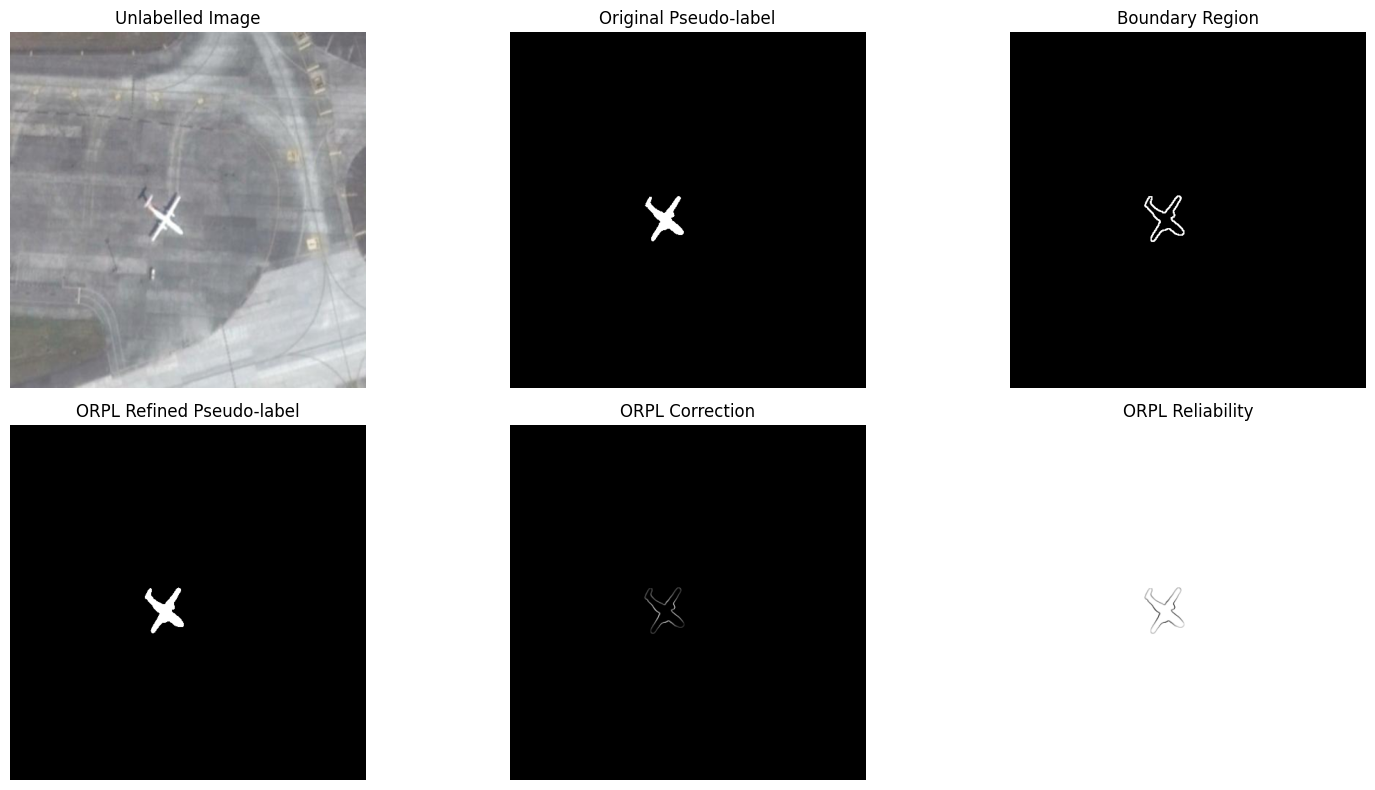

In [ ]:
pseudo_np = pseudo_mask[0, 0].cpu().numpy()
refined_np = refined_mask[0, 0].cpu().numpy()
boundary_np = boundary[0, 0].cpu().numpy()

difference_np = difference[0, 0].cpu().numpy()
reliability_np = reliability[0, 0].cpu().numpy()

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(image.permute(1, 2, 0).numpy())
plt.title("Unlabelled Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(pseudo_np, cmap="gray")
plt.title("Original Pseudo-label")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(boundary_np, cmap="gray")
plt.title("Boundary Region")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(refined_np, cmap="gray")
plt.title("ORPL Refined Pseudo-label")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(difference_np, cmap="gray")
plt.title("ORPL Correction")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(reliability_np, cmap="gray")
plt.title("ORPL Reliability")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def strong_augment(image):

    if random.random() < 0.7:
        image = TF.adjust_brightness(
            image,
            brightness_factor=random.uniform(0.6, 1.4)
        )

    if random.random() < 0.7:
        image = TF.adjust_contrast(
            image,
            contrast_factor=random.uniform(0.6, 1.4)
        )

    if random.random() < 0.5:
        image = TF.adjust_saturation(
            image,
            saturation_factor=random.uniform(0.7, 1.3)
        )

    if random.random() < 0.5:
        image = TF.adjust_gamma(
            image,
            gamma=random.uniform(0.8, 1.2)
        )

    return image

In [ ]:
def unsupervised_orpl_loss(
    strong_pred,
    refined_prob,
    reliability,
    confidence_threshold=0.95
):

    pseudo_label = (
        refined_prob.detach() > 0.5
    ).float()

    confidence = torch.where(
        (refined_prob.detach() >= confidence_threshold) |
        (refined_prob.detach() <= 1 - confidence_threshold),
        torch.ones_like(refined_prob),
        torch.zeros_like(refined_prob)
    )

    weights = reliability.detach() * confidence

    # Weighted BCE
    bce = F.binary_cross_entropy_with_logits(
        strong_pred,
        pseudo_label,
        reduction="none"
    )

    bce = (
        (bce * weights).sum()
        / (weights.sum() + 1e-6)
    )

    # Weighted Dice
    pred_prob = torch.sigmoid(strong_pred)

    intersection = (
        pred_prob * pseudo_label * weights
    ).sum(dim=(1, 2, 3))

    denominator = (
        pred_prob * weights
    ).sum(dim=(1, 2, 3)) + (
        pseudo_label * weights
    ).sum(dim=(1, 2, 3))

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    dice_loss_value = 1 - dice.mean()

    return bce + dice_loss_value

In [ ]:
model.eval()

images, _ = next(iter(unlabeled_loader))

images = images.to(device)

# Weak images
weak_images = torch.stack([
    weak_augment(img.cpu()).to(device)
    for img in images
])

# Strong images
strong_images = torch.stack([
    strong_augment(img.cpu()).to(device)
    for img in images
])

with torch.no_grad():

    weak_seg, _, weak_offsets = model(
        weak_images
    )

    weak_prob = torch.sigmoid(weak_seg)

    pseudo_mask = (
        weak_prob > 0.5
    ).float()

    boundary = get_boundary_band(
        pseudo_mask
    )

    refined_prob, reliability = rectify_pseudo_label(
        weak_prob,
        weak_offsets.detach(),
        boundary
    )

# Strong prediction
strong_seg, _, _ = model(
    strong_images
)

unsup_loss = unsupervised_orpl_loss(
    strong_seg,
    refined_prob,
    reliability
)

print("Unsupervised ORPL loss:", unsup_loss.item())

Unsupervised ORPL loss: 0.717306911945343


In [ ]:
LAMBDA_UNSUP = 0.5

def combined_semi_supervised_loss(
    supervised_total,
    unsupervised_loss
):
    return (
        supervised_total
        + LAMBDA_UNSUP * unsupervised_loss
    )

In [ ]:
model.train()

# -------------------------
# Labelled batch
# -------------------------

labeled_images, labeled_masks = next(
    iter(labeled_loader)
)

labeled_images = labeled_images.to(device)
labeled_masks = labeled_masks.to(device)

seg_pred, edge_pred, offset_pred = model(
    labeled_images
)

target_offsets, boundary = create_fast_offset_target(
    labeled_masks,
    max_offset=10
)

supervised_total, seg_loss, edge_loss, off_loss = (
    full_supervised_loss(
        seg_pred,
        edge_pred,
        offset_pred,
        labeled_masks,
        target_offsets,
        boundary
    )
)


# -------------------------
# Unlabelled batch
# -------------------------

unlabeled_images, _ = next(
    iter(unlabeled_loader)
)

unlabeled_images = unlabeled_images.to(device)

weak_images = torch.stack([
    weak_augment(img.cpu()).to(device)
    for img in unlabeled_images
])

strong_images = torch.stack([
    strong_augment(img.cpu()).to(device)
    for img in unlabeled_images
])


with torch.no_grad():

    weak_seg, _, weak_offsets = model(
        weak_images
    )

    weak_prob = torch.sigmoid(
        weak_seg
    )

    pseudo_mask = (
        weak_prob > 0.5
    ).float()

    boundary = get_boundary_band(
        pseudo_mask
    )

    refined_prob, reliability = (
        rectify_pseudo_label(
            weak_prob,
            weak_offsets.detach(),
            boundary
        )
    )


strong_seg, _, _ = model(
    strong_images
)

unsup_loss = unsupervised_orpl_loss(
    strong_seg,
    refined_prob,
    reliability
)


# -------------------------
# Combined loss
# -------------------------

total_loss = combined_semi_supervised_loss(
    supervised_total,
    unsup_loss
)

print("Supervised loss :", supervised_total.item())
print("Unsupervised loss:", unsup_loss.item())
print("Total loss       :", total_loss.item())

Supervised loss : 0.5169954895973206
Unsupervised loss: 0.8419880270957947
Total loss       : 0.9379894733428955


In [ ]:
def discriminator_loss(real_pred, fake_pred):

    real_target = torch.ones_like(real_pred)
    fake_target = torch.zeros_like(fake_pred)

    real_loss = F.binary_cross_entropy_with_logits(
        real_pred,
        real_target
    )

    fake_loss = F.binary_cross_entropy_with_logits(
        fake_pred,
        fake_target
    )

    return 0.5 * (real_loss + fake_loss)

In [ ]:
discriminator = PatchDiscriminator().to(device)

d_optimizer = torch.optim.Adam(
    discriminator.parameters(),
    lr=1e-4
)

print("Discriminator ready.")

Discriminator ready.


In [ ]:
discriminator.train()

# Get one labelled batch
labeled_images, labeled_masks = next(
    iter(labeled_loader)
)

labeled_masks = labeled_masks.to(device)

# Get one unlabelled batch
unlabeled_images, _ = next(
    iter(unlabeled_loader)
)

unlabeled_images = unlabeled_images.to(device)

# Generate ORPL pseudo-labels
with torch.no_grad():

    weak_images = torch.stack([
        weak_augment(img.cpu()).to(device)
        for img in unlabeled_images
    ])

    weak_seg, _, weak_offsets = model(
        weak_images
    )

    weak_prob = torch.sigmoid(weak_seg)

    pseudo_mask = (
        weak_prob > 0.5
    ).float()

    boundary = get_boundary_band(
        pseudo_mask
    )

    refined_prob, reliability = rectify_pseudo_label(
        weak_prob,
        weak_offsets.detach(),
        boundary
    )

    refined_mask = (
        refined_prob > 0.5
    ).float()


# Discriminator predictions
real_pred = discriminator(
    labeled_masks
)

fake_pred = discriminator(
    refined_mask.detach()
)

# Discriminator loss
d_loss = discriminator_loss(
    real_pred,
    fake_pred
)

d_optimizer.zero_grad()
d_loss.backward()
d_optimizer.step()

print("Real prediction shape :", real_pred.shape)
print("Fake prediction shape :", fake_pred.shape)
print("Discriminator loss    :", d_loss.item())

Real prediction shape : torch.Size([4, 1, 63, 63])
Fake prediction shape : torch.Size([4, 1, 63, 63])
Discriminator loss    : 0.7258420586585999


In [ ]:
with torch.no_grad():

    disc_score = torch.sigmoid(
        discriminator(refined_mask)
    )

    disc_gate = (
        disc_score > 0.5
    ).float()

    disc_gate = F.interpolate(
        disc_gate,
        size=(512, 512),
        mode="bilinear",
        align_corners=False
    )

print("Discriminator score shape:",
      disc_score.shape)

print("Discriminator gate shape:",
      disc_gate.shape)

print("Average discriminator score:",
      disc_score.mean().item())

print("Average discriminator gate:",
      disc_gate.mean().item())

Discriminator score shape: torch.Size([4, 1, 63, 63])
Discriminator gate shape: torch.Size([4, 1, 512, 512])
Average discriminator score: 0.5099159479141235
Average discriminator gate: 0.901552677154541


In [ ]:
def apply_discriminator_gate(
    reliability,
    discriminator_gate
):
    return reliability * discriminator_gate

In [ ]:
final_reliability = apply_discriminator_gate(
    reliability,
    disc_gate
)

print(
    "ORPL reliability:",
    reliability.mean().item()
)

print(
    "Discriminator gate:",
    disc_gate.mean().item()
)

print(
    "Final reliability:",
    final_reliability.mean().item()
)

ORPL reliability: 0.9995993971824646
Discriminator gate: 0.901552677154541
Final reliability: 0.901435136795044


In [ ]:
def unsupervised_orpl_loss(
    strong_pred,
    refined_prob,
    reliability,
    discriminator_gate,
    confidence_threshold=0.95
):

    pseudo_label = (
        refined_prob.detach() > 0.5
    ).float()

    confidence = torch.where(
        (refined_prob.detach() >= confidence_threshold) |
        (refined_prob.detach() <= 1 - confidence_threshold),
        torch.ones_like(refined_prob),
        torch.zeros_like(refined_prob)
    )

    weights = (
        reliability.detach()
        * discriminator_gate.detach()
        * confidence
    )

    bce = F.binary_cross_entropy_with_logits(
        strong_pred,
        pseudo_label,
        reduction="none"
    )

    bce = (
        (bce * weights).sum()
        / (weights.sum() + 1e-6)
    )

    pred_prob = torch.sigmoid(strong_pred)

    intersection = (
        pred_prob
        * pseudo_label
        * weights
    ).sum(dim=(1, 2, 3))

    denominator = (
        pred_prob * weights
    ).sum(dim=(1, 2, 3)) + (
        pseudo_label * weights
    ).sum(dim=(1, 2, 3))

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    dice_loss_value = 1 - dice.mean()

    return bce + dice_loss_value

In [ ]:
gated_unsup_loss = unsupervised_orpl_loss(
    strong_seg,
    refined_prob,
    reliability,
    disc_gate
)

print("Gated unsupervised loss:", gated_unsup_loss.item())

Gated unsupervised loss: 1.1369168758392334


In [ ]:
total_generator_loss = (
    supervised_total
    + LAMBDA_UNSUP * gated_unsup_loss
)

print("Supervised loss       :", supervised_total.item())
print("Gated unsupervised    :", gated_unsup_loss.item())
print("Total generator loss  :", total_generator_loss.item())

Supervised loss       : 0.5169954895973206
Gated unsupervised    : 1.1369168758392334
Total generator loss  : 1.085453987121582


In [ ]:
LAMBDA_UNSUP = 0.5

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_supervised_ORPL.pth",
        map_location=device
    )
)

model.train()
discriminator.train()

g_optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

d_optimizer = torch.optim.Adam(
    discriminator.parameters(),
    lr=1e-4
)

LAMBDA_UNSUP = 0.5

In [ ]:
from itertools import cycle

num_epochs = 1

for epoch in range(num_epochs):

    model.train()
    discriminator.train()

    running_g_loss = 0
    running_sup = 0
    running_unsup = 0
    running_d = 0

    unlabeled_iter = cycle(unlabeled_loader)

    for labeled_images, labeled_masks in labeled_loader:

        labeled_images = labeled_images.to(device)
        labeled_masks = labeled_masks.to(device)

        unlabeled_images, _ = next(unlabeled_iter)
        unlabeled_images = unlabeled_images.to(device)

        # =====================================
        # 1. SUPERVISED BRANCH
        # =====================================

        seg_pred, edge_pred, offset_pred = model(
            labeled_images
        )

        target_offsets, boundary = create_fast_offset_target(
            labeled_masks,
            max_offset=10
        )

        supervised_total, _, _, _ = full_supervised_loss(
            seg_pred,
            edge_pred,
            offset_pred,
            labeled_masks,
            target_offsets,
            boundary
        )

        # =====================================
        # 2. WEAK UNLABELLED PREDICTION
        # =====================================

        weak_images = torch.stack([
            weak_augment(img.cpu()).to(device)
            for img in unlabeled_images
        ])

        with torch.no_grad():

            weak_seg, _, weak_offsets = model(
                weak_images
            )

            weak_prob = torch.sigmoid(
                weak_seg
            )

            pseudo_mask = (
                weak_prob > 0.5
            ).float()

            pseudo_boundary = get_boundary_band(
                pseudo_mask
            )

            refined_prob, reliability = (
                rectify_pseudo_label(
                    weak_prob,
                    weak_offsets.detach(),
                    pseudo_boundary
                )
            )

            refined_mask = (
                refined_prob > 0.5
            ).float()

        # =====================================
        # 3. UPDATE DISCRIMINATOR
        # =====================================

        real_pred = discriminator(
            labeled_masks
        )

        fake_pred = discriminator(
            refined_mask.detach()
        )

        d_loss = discriminator_loss(
            real_pred,
            fake_pred
        )

        d_optimizer.zero_grad()
        d_loss.backward()
        d_optimizer.step()

        # =====================================
        # 4. DISCRIMINATOR GATE
        # =====================================

        with torch.no_grad():

            disc_score = torch.sigmoid(
                discriminator(refined_mask)
            )

            disc_gate = F.interpolate(
                (disc_score > 0.5).float(),
                size=(512, 512),
                mode="bilinear",
                align_corners=False
            )

        # =====================================
        # 5. STRONG UNLABELLED PREDICTION
        # =====================================

        strong_images = torch.stack([
            strong_augment(img.cpu()).to(device)
            for img in unlabeled_images
        ])

        strong_seg, _, _ = model(
            strong_images
        )

        unsup_loss = unsupervised_orpl_loss(
            strong_seg,
            refined_prob,
            reliability,
            disc_gate
        )

        # =====================================
        # 6. GENERATOR UPDATE
        # =====================================

        total_generator_loss = (
            supervised_total
            + LAMBDA_UNSUP * unsup_loss
        )

        g_optimizer.zero_grad()
        total_generator_loss.backward()
        g_optimizer.step()

        # =====================================
        # TRACK LOSSES
        # =====================================

        running_g_loss += total_generator_loss.item()
        running_sup += supervised_total.item()
        running_unsup += unsup_loss.item()
        running_d += d_loss.item()

    n = len(labeled_loader)

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print(
        "Generator Loss :",
        running_g_loss / n
    )
    print(
        "Supervised Loss:",
        running_sup / n
    )
    print(
        "Unsupervised Loss:",
        running_unsup / n
    )
    print(
        "Discriminator Loss:",
        running_d / n
    )


Epoch 1/1
Generator Loss : 1.0885862112045288
Supervised Loss: 0.6714427646190401
Unsupervised Loss: 0.8342868908057137
Discriminator Loss: 0.6969388051638528


In [ ]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_supervised_ORPL.pth",
        map_location=device
    )
)

discriminator = PatchDiscriminator().to(device)

g_optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

d_optimizer = torch.optim.Adam(
    discriminator.parameters(),
    lr=1e-4
)

print("Clean SSL starting point loaded.")

Clean SSL starting point loaded.


In [ ]:
num_epochs = 10

best_ssl_miou = 0.0

ssl_history = {
    "generator_loss": [],
    "supervised_loss": [],
    "unsupervised_loss": [],
    "discriminator_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_f1": []
}

for epoch in range(num_epochs):

    model.train()
    discriminator.train()

    running_g = 0.0
    running_sup = 0.0
    running_unsup = 0.0
    running_d = 0.0

    unlabeled_iter = cycle(unlabeled_loader)

    for labeled_images, labeled_masks in labeled_loader:

        labeled_images = labeled_images.to(device)
        labeled_masks = labeled_masks.to(device)

        unlabeled_images, _ = next(unlabeled_iter)
        unlabeled_images = unlabeled_images.to(device)

        # ==========================================
        # 1. SUPERVISED BRANCH
        # ==========================================

        seg_pred, edge_pred, offset_pred = model(
            labeled_images
        )

        target_offsets, boundary = create_fast_offset_target(
            labeled_masks,
            max_offset=10
        )

        supervised_total, _, _, _ = full_supervised_loss(
            seg_pred,
            edge_pred,
            offset_pred,
            labeled_masks,
            target_offsets,
            boundary
        )

        # ==========================================
        # 2. WEAK UNLABELLED PREDICTION
        # ==========================================

        weak_images = torch.stack([
            weak_augment(img.cpu()).to(device)
            for img in unlabeled_images
        ])

        with torch.no_grad():

            weak_seg, _, weak_offsets = model(
                weak_images
            )

            weak_prob = torch.sigmoid(weak_seg)

            pseudo_mask = (
                weak_prob > 0.5
            ).float()

            pseudo_boundary = get_boundary_band(
                pseudo_mask
            )

            refined_prob, reliability = (
                rectify_pseudo_label(
                    weak_prob,
                    weak_offsets.detach(),
                    pseudo_boundary
                )
            )

            refined_mask = (
                refined_prob > 0.5
            ).float()

        # ==========================================
        # 3. DISCRIMINATOR UPDATE
        # ==========================================

        real_pred = discriminator(
            labeled_masks
        )

        fake_pred = discriminator(
            refined_mask.detach()
        )

        d_loss = discriminator_loss(
            real_pred,
            fake_pred
        )

        d_optimizer.zero_grad()
        d_loss.backward()
        d_optimizer.step()

        # ==========================================
        # 4. DISCRIMINATOR GATE
        # ==========================================

        with torch.no_grad():

            disc_score = torch.sigmoid(
                discriminator(refined_mask)
            )

            disc_gate = F.interpolate(
                (disc_score > 0.5).float(),
                size=(512, 512),
                mode="bilinear",
                align_corners=False
            )

        # ==========================================
        # 5. STRONG UNLABELLED PREDICTION
        # ==========================================

        strong_images = torch.stack([
            strong_augment(img.cpu()).to(device)
            for img in unlabeled_images
        ])

        strong_seg, _, _ = model(
            strong_images
        )

        unsup_loss = unsupervised_orpl_loss(
            strong_seg,
            refined_prob,
            reliability,
            disc_gate
        )

        # ==========================================
        # 6. GENERATOR UPDATE
        # ==========================================

        total_generator_loss = (
            supervised_total
            + LAMBDA_UNSUP * unsup_loss
        )

        g_optimizer.zero_grad()
        total_generator_loss.backward()
        g_optimizer.step()

        running_g += total_generator_loss.item()
        running_sup += supervised_total.item()
        running_unsup += unsup_loss.item()
        running_d += d_loss.item()

    n = len(labeled_loader)

    avg_g = running_g / n
    avg_sup = running_sup / n
    avg_unsup = running_unsup / n
    avg_d = running_d / n

    # ==========================================
    # 7. VALIDATION
    # ==========================================

    val_loss, val_miou, val_f1 = validate(
        model,
        val_loader
    )

    ssl_history["generator_loss"].append(avg_g)
    ssl_history["supervised_loss"].append(avg_sup)
    ssl_history["unsupervised_loss"].append(avg_unsup)
    ssl_history["discriminator_loss"].append(avg_d)
    ssl_history["val_loss"].append(val_loss)
    ssl_history["val_miou"].append(val_miou)
    ssl_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Generator Loss     : {avg_g:.4f}")
    print(f"Supervised Loss    : {avg_sup:.4f}")
    print(f"Unsupervised Loss  : {avg_unsup:.4f}")
    print(f"Discriminator Loss : {avg_d:.4f}")
    print(f"Val Loss           : {val_loss:.4f}")
    print(f"Val mIoU           : {val_miou:.4f}")
    print(f"Val F1             : {val_f1:.4f}")

    # ==========================================
    # 8. SAVE BEST SSL MODEL
    # ==========================================

    if val_miou > best_ssl_miou:

        best_ssl_miou = val_miou

        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/EORSSD_best_SSL_ORPL.pth"
        )

        print("✓ Best SSL model saved")


Epoch 1/10
Generator Loss     : 1.1237
Supervised Loss    : 0.6997
Unsupervised Loss  : 0.8480
Discriminator Loss : 0.6980
Val Loss           : 0.5722
Val mIoU           : 0.5549
Val F1             : 0.6533
✓ Best SSL model saved

Epoch 2/10
Generator Loss     : 1.1173
Supervised Loss    : 0.6606
Unsupervised Loss  : 0.9134
Discriminator Loss : 0.6939
Val Loss           : 0.5764
Val mIoU           : 0.5799
Val F1             : 0.6746
✓ Best SSL model saved

Epoch 3/10
Generator Loss     : 1.1026
Supervised Loss    : 0.6568
Unsupervised Loss  : 0.8917
Discriminator Loss : 0.6928
Val Loss           : 0.5914
Val mIoU           : 0.5496
Val F1             : 0.6444

Epoch 4/10
Generator Loss     : 1.0930
Supervised Loss    : 0.6322
Unsupervised Loss  : 0.9215
Discriminator Loss : 0.6935
Val Loss           : 0.4831
Val mIoU           : 0.6247
Val F1             : 0.7199
✓ Best SSL model saved

Epoch 5/10
Generator Loss     : 1.0735
Supervised Loss    : 0.6470
Unsupervised Loss  : 0.8531
Dis

In [ ]:
# ============================================
# FINAL TEST EVALUATION — ENHANCED BROIE
# ============================================

best_model = EORSSDGenerator().to(device)

best_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EORSSD_best_SSL_ORPL.pth",
        map_location=device
    )
)

best_model.eval()

total_intersection = 0.0
total_union = 0.0
total_tp = 0.0
total_fp = 0.0
total_fn = 0.0
total_loss = 0.0
num_batches = 0

bce = torch.nn.BCEWithLogitsLoss()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        seg_pred, _, _ = best_model(images)

        loss = dice_loss(seg_pred, masks) + bce(seg_pred, masks)

        total_loss += loss.item()
        num_batches += 1

        pred = (torch.sigmoid(seg_pred) > 0.5).float()
        target = (masks > 0.5).float()

        intersection = (pred * target).sum().item()

        union = (
            pred.sum().item()
            + target.sum().item()
            - intersection
        )

        tp = (pred * target).sum().item()
        fp = (pred * (1 - target)).sum().item()
        fn = ((1 - pred) * target).sum().item()

        total_intersection += intersection
        total_union += union
        total_tp += tp
        total_fp += fp
        total_fn += fn


# ============================================
# METRICS
# ============================================

test_loss = total_loss / num_batches

test_miou = (
    total_intersection /
    (total_union + 1e-8)
)

test_precision = (
    total_tp /
    (total_tp + total_fp + 1e-8)
)

test_recall = (
    total_tp /
    (total_tp + total_fn + 1e-8)
)

test_f1 = (
    2 * test_precision * test_recall /
    (test_precision + test_recall + 1e-8)
)


# ============================================
# RESULTS
# ============================================

print("=" * 55)
print("FINAL ENHANCED BROIE — EORSSD TEST RESULTS")
print("=" * 55)

print(f"Test Loss  : {test_loss:.4f}")
print(f"mIoU       : {test_miou:.4f}")
print(f"F1 Score   : {test_f1:.4f}")
print(f"Precision  : {test_precision:.4f}")
print(f"Recall     : {test_recall:.4f}")

print("=" * 55)

FINAL ENHANCED BROIE — EORSSD TEST RESULTS
Test Loss  : 0.5078
mIoU       : 0.4774
F1 Score   : 0.6463
Precision  : 0.6253
Recall     : 0.6688


Best Enhanced BROIE + ORPL model loaded.
Checkpoint: Epoch 4
Validation mIoU: 0.6247
Validation F1: 0.7199

Starting testing on 600 test images...
Processed 80/600 images
Processed 160/600 images
Processed 240/600 images
Processed 320/600 images
Processed 400/600 images
Processed 480/600 images
Processed 560/600 images


FINAL EORSSD TEST RESULTS
Test Loss   : 0.5078
mIoU        : 0.4774
F1 Score    : 0.6463
Precision   : 0.6253
Recall      : 0.6688

Generating segmentation visualizations...


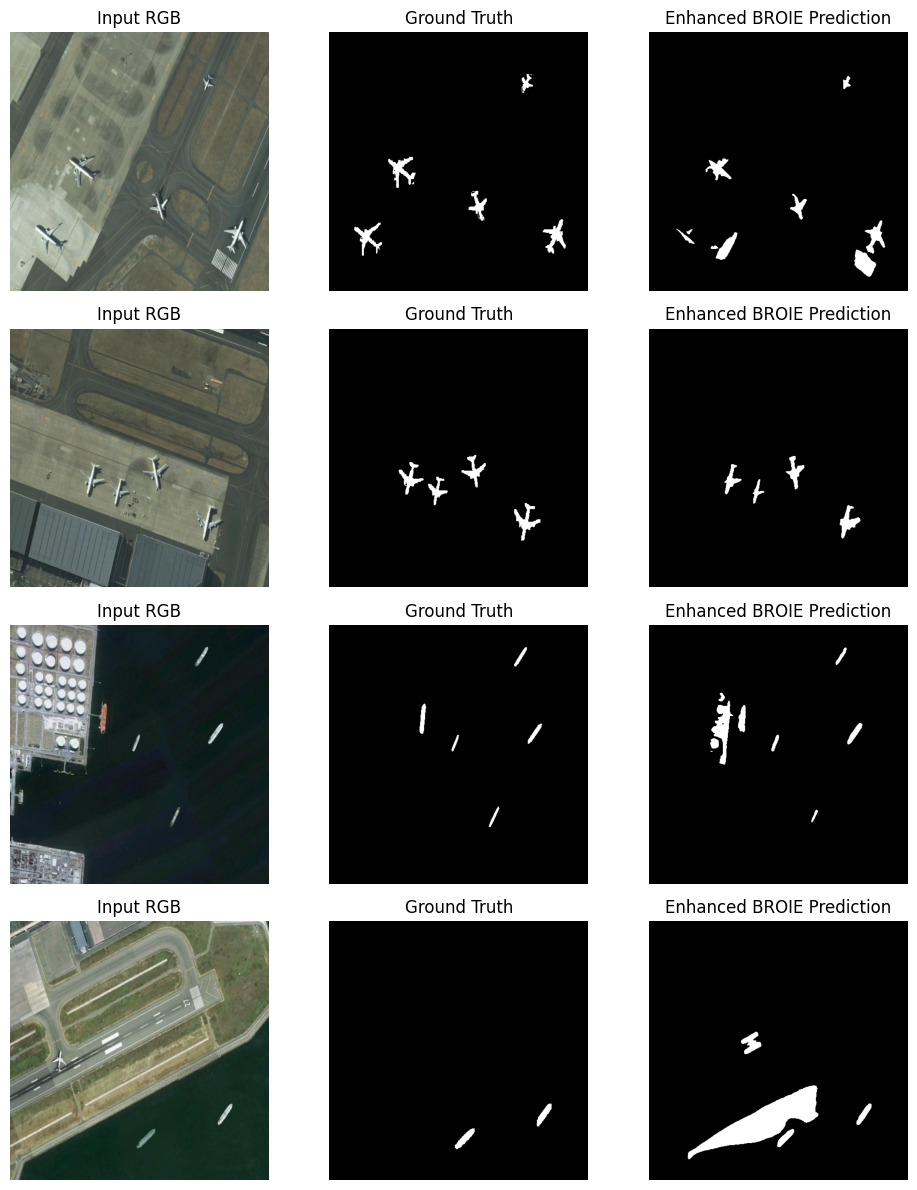



EORSSD COMPLETE

Test images evaluated : 600

Best checkpoint       : Epoch 4

Validation mIoU       : 0.6247
Validation F1         : 0.7199

Final Test mIoU       : 0.4774
Final Test F1         : 0.6463
Final Test Precision   : 0.6253
Final Test Recall      : 0.6688

Predicted masks saved:
/content/drive/MyDrive/EORSSD_Final_Results/predicted_masks

Visualizations saved:
/content/drive/MyDrive/EORSSD_Final_Results/visualizations

Metrics saved:
/content/drive/MyDrive/EORSSD_Final_Results/final_test_metrics.csv

Testing and segmentation-mask generation completed.


In [ ]:
# ============================================================
# FINAL EORSSD TESTING
# Enhanced BROIE + ORPL
# Metrics + Segmentation Masks + Visualizations
# ============================================================

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

CHECKPOINT = "/content/drive/MyDrive/EORSSD_best_SSL_ORPL.pth"

RESULT_DIR = "/content/drive/MyDrive/EORSSD_Final_Results"
MASK_DIR = os.path.join(RESULT_DIR, "predicted_masks")
VIS_DIR = os.path.join(RESULT_DIR, "visualizations")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(VIS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Load best model
# ------------------------------------------------------------

model = EORSSDGenerator().to(device)

model.load_state_dict(
    torch.load(
        CHECKPOINT,
        map_location=device
    )
)

model.eval()

print("Best Enhanced BROIE + ORPL model loaded.")
print("Checkpoint: Epoch 4")
print("Validation mIoU: 0.6247")
print("Validation F1: 0.7199")


# ------------------------------------------------------------
# 3. Test evaluation
# ------------------------------------------------------------

total_intersection = 0.0
total_union = 0.0
total_tp = 0.0
total_fp = 0.0
total_fn = 0.0
total_loss = 0.0

num_batches = 0

bce = torch.nn.BCEWithLogitsLoss()

all_results = []

print("\nStarting testing on 600 test images...")


with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(test_loader):

        images = images.to(device)
        masks = masks.to(device)

        # --------------------------------------------
        # Model prediction
        # --------------------------------------------

        seg_pred, edge_pred, offset_pred = model(images)

        probabilities = torch.sigmoid(seg_pred)

        predicted_masks = (
            probabilities > 0.5
        ).float()

        ground_truth = (
            masks > 0.5
        ).float()

        # --------------------------------------------
        # Batch loss
        # --------------------------------------------

        loss = (
            dice_loss(seg_pred, masks)
            + bce(seg_pred, masks)
        )

        total_loss += loss.item()
        num_batches += 1

        # --------------------------------------------
        # Batch metrics
        # --------------------------------------------

        intersection = (
            predicted_masks * ground_truth
        ).sum().item()

        union = (
            predicted_masks.sum().item()
            + ground_truth.sum().item()
            - intersection
        )

        tp = (
            predicted_masks * ground_truth
        ).sum().item()

        fp = (
            predicted_masks * (1 - ground_truth)
        ).sum().item()

        fn = (
            (1 - predicted_masks) * ground_truth
        ).sum().item()

        total_intersection += intersection
        total_union += union
        total_tp += tp
        total_fp += fp
        total_fn += fn

        # --------------------------------------------
        # Save predicted masks
        # --------------------------------------------

        for i in range(images.size(0)):

            global_index = (
                batch_idx * test_loader.batch_size
                + i
                + 1
            )

            mask_array = (
                predicted_masks[i, 0]
                .cpu()
                .numpy()
                .astype(np.uint8)
                * 255
            )

            mask_image = Image.fromarray(
                mask_array
            )

            mask_path = os.path.join(
                MASK_DIR,
                f"{global_index:04d}.png"
            )

            mask_image.save(mask_path)

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Processed "
                f"{min((batch_idx + 1) * test_loader.batch_size, 600)}"
                f"/600 images"
            )


# ------------------------------------------------------------
# 4. Calculate final metrics
# ------------------------------------------------------------

test_loss = (
    total_loss / num_batches
)

test_miou = (
    total_intersection /
    (total_union + 1e-8)
)

test_precision = (
    total_tp /
    (total_tp + total_fp + 1e-8)
)

test_recall = (
    total_tp /
    (total_tp + total_fn + 1e-8)
)

test_f1 = (
    2 * test_precision * test_recall /
    (test_precision + test_recall + 1e-8)
)


# ------------------------------------------------------------
# 5. Print final results
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("FINAL EORSSD TEST RESULTS")
print("=" * 60)

print(f"Test Loss   : {test_loss:.4f}")
print(f"mIoU        : {test_miou:.4f}")
print(f"F1 Score    : {test_f1:.4f}")
print(f"Precision   : {test_precision:.4f}")
print(f"Recall      : {test_recall:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# 6. Save metrics
# ------------------------------------------------------------

results = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "mIoU",
        "F1 Score",
        "Precision",
        "Recall"
    ],
    "Value": [
        test_loss,
        test_miou,
        test_f1,
        test_precision,
        test_recall
    ]
})

results_path = os.path.join(
    RESULT_DIR,
    "final_test_metrics.csv"
)

results.to_csv(
    results_path,
    index=False
)


# ------------------------------------------------------------
# 7. Generate qualitative visualizations
# ------------------------------------------------------------

print("\nGenerating segmentation visualizations...")

model.eval()

# Take first few test batches
images, masks = next(iter(test_loader))

images_device = images.to(device)

with torch.no_grad():

    seg_pred, _, _ = model(
        images_device
    )

    predictions = (
        torch.sigmoid(seg_pred) > 0.5
    ).float().cpu()


num_examples = min(
    6,
    images.size(0)
)

fig, axes = plt.subplots(
    num_examples,
    3,
    figsize=(10, 3 * num_examples)
)

if num_examples == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for i in range(num_examples):

    image = (
        images[i]
        .permute(1, 2, 0)
        .numpy()
    )

    ground_truth = (
        masks[i, 0]
        .numpy()
    )

    prediction = (
        predictions[i, 0]
        .numpy()
    )

    # Input
    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Input RGB")
    axes[i, 0].axis("off")

    # Ground truth
    axes[i, 1].imshow(
        ground_truth,
        cmap="gray"
    )
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    # Prediction
    axes[i, 2].imshow(
        prediction,
        cmap="gray"
    )
    axes[i, 2].set_title(
        "Enhanced BROIE Prediction"
    )
    axes[i, 2].axis("off")


plt.tight_layout()

visualization_path = os.path.join(
    VIS_DIR,
    "segmentation_results.png"
)

plt.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Save individual visualizations
# ------------------------------------------------------------

for i in range(num_examples):

    image = (
        images[i]
        .permute(1, 2, 0)
        .numpy()
    )

    ground_truth = (
        masks[i, 0]
        .numpy()
    )

    prediction = (
        predictions[i, 0]
        .numpy()
    )

    fig, ax = plt.subplots(
        1,
        3,
        figsize=(12, 4)
    )

    ax[0].imshow(image)
    ax[0].set_title("Input RGB")
    ax[0].axis("off")

    ax[1].imshow(
        ground_truth,
        cmap="gray"
    )
    ax[1].set_title("Ground Truth")
    ax[1].axis("off")

    ax[2].imshow(
        prediction,
        cmap="gray"
    )
    ax[2].set_title(
        "Predicted ROI Mask"
    )
    ax[2].axis("off")

    plt.tight_layout()

    path = os.path.join(
        VIS_DIR,
        f"example_{i+1}.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("EORSSD COMPLETE")
print("=" * 60)

print(f"""
Test images evaluated : 600

Best checkpoint       : Epoch 4

Validation mIoU       : 0.6247
Validation F1         : 0.7199

Final Test mIoU       : {test_miou:.4f}
Final Test F1         : {test_f1:.4f}
Final Test Precision   : {test_precision:.4f}
Final Test Recall      : {test_recall:.4f}

Predicted masks saved:
{MASK_DIR}

Visualizations saved:
{VIS_DIR}

Metrics saved:
{results_path}
""")

print("Testing and segmentation-mask generation completed.")